In [1]:
# Jalankan perintah berikut jika paket belum terpasang:
!apt-get update -qq && apt-get install -y -qq tesseract-ocr tesseract-ocr-ind tesseract-ocr-eng
!pip install -q opencv-python numpy matplotlib scikit-image pandas pytesseract jiwer

import re
import zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.filters import threshold_sauvola

try:
    import pytesseract
    PYTESSERACT_TERSEDIA = True
except ImportError:
    PYTESSERACT_TERSEDIA = False
    print("[Info] pytesseract belum terpasang. Tahap OCR akan dilewati hingga pytesseract & tesseract-ocr diinstal.")

try:
    from jiwer import cer as hitung_cer_jiwer, wer as hitung_wer_jiwer
    JIWER_TERSEDIA = True
except ImportError:
    JIWER_TERSEDIA = False

plt.rcParams["figure.dpi"] = 110
print("OpenCV:", cv2.__version__, "| pytesseract:", PYTESSERACT_TERSEDIA, "| jiwer:", JIWER_TERSEDIA)

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...
OpenCV: 5.0.0 | pytesseract: True | jiwer: True


In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

def temukan_folder_proyek():
    if DI_COLAB:
        kandidat_colab = [
            Path("/content/drive/MyDrive/Semester 7/Pengolahan Citra Digital"),
            Path("/content/drive/MyDrive/Pengolahan Citra Digital"),
            Path("/content/drive/MyDrive/Semester 7/PCD"),
        ]
        for p in kandidat_colab:
            if p.exists():
                return p
        return kandidat_colab[0]
    else:
        cwd = Path.cwd().resolve()
        # Jika dijalankan dari dalam subfolder 'Notebook/', naik satu tingkat ke 'Pengolahan Citra Digital/'
        if cwd.name.lower() == "notebook" and (cwd.parent / "Dataset").exists():
            return cwd.parent
        if (cwd / "Dataset").exists():
            return cwd
        return cwd.parent if cwd.name.lower() == "notebook" else cwd

FOLDER_PROYEK = temukan_folder_proyek()
DATASET_DIR   = FOLDER_PROYEK / "Dataset"
LOKAL_DIR     = Path("/content/data_ekstrak") if DI_COLAB else (FOLDER_PROYEK / "data_ekstrak")
OUT_DIR       = FOLDER_PROYEK / "hasil_prapemrosesan"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Di Colab      :", DI_COLAB)
print("Folder Proyek :", FOLDER_PROYEK)
print("Folder Dataset:", DATASET_DIR)
print("Folder Output :", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Di Colab      : True
Folder Proyek : /content/drive/MyDrive/Semester 7/PCD
Folder Dataset: /content/drive/MyDrive/Semester 7/PCD/Dataset
Folder Output : /content/drive/MyDrive/Semester 7/PCD/hasil_prapemrosesan


In [3]:
# Konfigurasi 3 kelas dataset sesuai struktur folder proyek (nama folder di Google Drive)
#   "folder" = nama folder ASLI di Drive (dengan underscore)
#   "alias"  = nama alternatif yang tetap diterima (mis. versi dengan spasi atau file .zip)
KONFIG_KELAS = [
    {
        "folder": "Kertas_Polos-Baris",
        "alias": ["Kertas Polos-Baris"],
        "source_type": "primer",
        "class_name": "polos_single_line",
        "paper_type": "polos",
        "layout_type": "single_line",
        "has_lines": False,
    },
    {
        "folder": "Kertas_Bergaris-Baris",
        "alias": ["Kertas Bergaris-Baris"],
        "source_type": "primer",
        "class_name": "bergaris_single_line",
        "paper_type": "bergaris",
        "layout_type": "single_line",
        "has_lines": True,
    },
    {
        "folder": "Kertas_Bergaris",
        "alias": ["Kertas Bergaris"],
        "source_type": "primer",
        "class_name": "multi_line",
        "paper_type": "bergaris",
        "layout_type": "multi_line",
        "has_lines": True,
    },
    {
        "folder": "Sekunder",   # opsional (mis. subset IAM Handwriting)
        "alias": ["IAM_Subset"],
        "source_type": "sekunder",
        "class_name": "sekunder",
        "paper_type": "polos",
        "layout_type": "single_line",
        "has_lines": False,
    },
]

EKSTENSI = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def normalisasi_nama(nama):
    """Samakan penulisan nama: huruf kecil, tanpa '.zip', spasi/underscore dianggap sama.
    'Kertas Polos-Baris' == 'Kertas_Polos-Baris' == 'kertas_polos-baris.zip'"""
    nama = nama.strip().lower()
    if nama.endswith(".zip"):
        nama = nama[:-4]
    return re.sub(r"[\s_]+", "_", nama)

def cari_sumber_kelas(cfg):
    """Cari folder (atau .zip) kelas di DATASET_DIR lalu FOLDER_PROYEK.
    Pencocokan harus PERSIS (setelah dinormalisasi), sehingga 'Kertas_Bergaris'
    tidak salah menangkap folder 'Kertas_Bergaris-Baris'."""
    target = {normalisasi_nama(n) for n in [cfg["folder"], *cfg.get("alias", [])]}
    for base in [DATASET_DIR, FOLDER_PROYEK]:
        if not base.exists():
            continue
        for item in sorted(base.iterdir()):
            if (item.is_dir() or item.suffix.lower() == ".zip") and normalisasi_nama(item.name) in target:
                return item
    return None

def siapkan_folder_kelas(class_name, sumber):
    if sumber.is_dir():
        return sumber
    tujuan = LOKAL_DIR / class_name
    tujuan.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(sumber) as zf:
        for member in zf.infolist():
            nama = Path(member.filename).name
            if member.is_dir() or nama.startswith(".") or "__MACOSX" in member.filename:
                continue
            if Path(nama).suffix.lower() in EKSTENSI:
                (tujuan / nama).write_bytes(zf.read(member))
    return tujuan

def deteksi_garis_otomatis(img_bgr, min_rasio_lebar=0.35):
    """Mendeteksi apakah citra memiliki garis buku horizontal (berguna jika halaman polos digabung ke Kelas 3)."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    k = (max(gray.shape) // 20) | 1
    bg = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    norm = cv2.normalize(cv2.divide(gray, bg, scale=255), None, 0, 255, cv2.NORM_MINMAX)
    _, biner = cv2.threshold(norm, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    panjang = max(int(biner.shape[1] * min_rasio_lebar), 40)
    garis = cv2.morphologyEx(biner, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (panjang, 1)))
    return int((garis > 0).sum()) > panjang

records = []
for cfg in KONFIG_KELAS:
    sumber = cari_sumber_kelas(cfg)
    if sumber is None:
        if cfg["source_type"] == "primer":
            tersedia = sorted(p.name for p in DATASET_DIR.iterdir()) if DATASET_DIR.exists() else "(folder Dataset tidak ada)"
            print(f"[!] Folder/zip '{cfg['folder']}' tidak ditemukan di {DATASET_DIR}.")
            print(f"    Isi folder Dataset saat ini: {tersedia}")
        continue
    folder_aktif = siapkan_folder_kelas(cfg["class_name"], sumber)
    file_citra = [
        f for f in sorted(folder_aktif.rglob("*"))
        if f.suffix.lower() in EKSTENSI and not f.name.startswith(".")
    ]
    print(f"{cfg['class_name']:21s} ({cfg['folder']}): {len(file_citra)} citra <- {sumber}")
    for idx, f in enumerate(file_citra, start=1):
        img = cv2.imread(str(f))
        if img is None:
            continue
        kode = f.stem.split("_")[0] if "_" in f.stem else f.stem
        image_id = f"{cfg['class_name']}_{kode}_{idx:02d}"
        # Untuk multi_line, verifikasi apakah citra benar-benar memiliki garis buku atau halaman polos
        ada_garis = cfg["has_lines"]
        if cfg["layout_type"] == "multi_line":
            ada_garis = deteksi_garis_otomatis(img)
        records.append({
            "image_id": image_id,
            "source_type": cfg["source_type"],
            "class_name": cfg["class_name"],
            "folder_asal": cfg["folder"],
            "paper_type": "bergaris" if ada_garis else "polos",
            "layout_type": cfg["layout_type"],
            "has_lines": ada_garis,
            "kode": kode,
            "file": f.name,
            "path": f,
            "tinggi": img.shape[0],
            "lebar": img.shape[1],
            "citra": img,
        })

df = pd.DataFrame(records)
print(f"\nTotal citra berhasil dimuat: {len(df)}")
if len(df) == 0:
    raise FileNotFoundError("Tidak ada citra yang termuat. Periksa nama folder pada KONFIG_KELAS dan isi DATASET_DIR.")
df[["image_id", "source_type", "class_name", "paper_type", "layout_type", "has_lines", "file", "tinggi", "lebar"]]

polos_single_line     (Kertas_Polos-Baris): 7 citra <- /content/drive/MyDrive/Semester 7/PCD/Kertas_Polos-Baris
bergaris_single_line  (Kertas_Bergaris-Baris): 7 citra <- /content/drive/MyDrive/Semester 7/PCD/Kertas_Bergaris-Baris
multi_line            (Kertas_Bergaris): 10 citra <- /content/drive/MyDrive/Semester 7/PCD/Kertas_Bergaris

Total citra berhasil dimuat: 24


,image_id,source_type,class_name,paper_type,layout_type,has_lines,file,tinggi,lebar
0,polos_single_line_K01_01,primer,polos_single_line,polos,single_line,False,K01_Kamera_HP.jpeg,174,1600
1,polos_single_line_K02_02,primer,polos_single_line,polos,single_line,False,K02_Kamera_HP.jpeg,214,1600
2,polos_single_line_K03_03,primer,polos_single_line,polos,single_line,False,K03_Kamera_HP.jpeg,177,1600
3,polos_single_line_K04_04,primer,polos_single_line,polos,single_line,False,K04_Kamera_HP.jpeg,168,1600
4,polos_single_line_K05_05,primer,polos_single_line,polos,single_line,False,K05_Kamera_HP.jpeg,149,1600
5,polos_single_line_K06_06,primer,polos_single_line,polos,single_line,False,K06_Kamera_HP.jpeg,163,1600
6,polos_single_line_K07_07,primer,polos_single_line,polos,single_line,False,K07_Kamera_HP.jpeg,133,1600
7,bergaris_single_line_K01_01,primer,bergaris_single_line,bergaris,single_line,True,K01_Kamera_HP.jpeg,251,1599
8,bergaris_single_line_K02_02,primer,bergaris_single_line,bergaris,single_line,True,K02_Kamera_HP.jpeg,276,1599
9,bergaris_single_line_K03_03,primer,bergaris_single_line,bergaris,single_line,True,K03_Kamera_HP.jpeg,355,1599


In [4]:
# Muat atau buat template ground_truth.csv di folder Dataset
GT_PATH = DATASET_DIR / "ground_truth.csv"

if len(df) > 0:
    if GT_PATH.exists():
        df_gt = pd.read_csv(GT_PATH)
        # Gabungkan berdasarkan image_id jika ada, atau berdasarkan (folder_asal, file)
        if "image_id" in df_gt.columns and df_gt["image_id"].isin(df["image_id"]).any():
            df = df.merge(df_gt[["image_id", "ground_truth"]].drop_duplicates("image_id"), on="image_id", how="left")
        elif {"folder_asal", "file", "ground_truth"}.issubset(df_gt.columns):
            # Nama folder dinormalisasi agar 'Kertas Polos-Baris' & 'Kertas_Polos-Baris' dianggap sama
            df["_kunci_folder"] = df["folder_asal"].map(normalisasi_nama)
            gt_kunci = df_gt[["folder_asal", "file", "ground_truth"]].copy()
            gt_kunci["_kunci_folder"] = gt_kunci["folder_asal"].map(normalisasi_nama)
            gt_kunci = gt_kunci.drop_duplicates(["_kunci_folder", "file"])[["_kunci_folder", "file", "ground_truth"]]
            df = df.merge(gt_kunci, on=["_kunci_folder", "file"], how="left").drop(columns="_kunci_folder")
        else:
            df["ground_truth"] = ""
        df["ground_truth"] = df["ground_truth"].fillna("")
        print(f"Ground truth dimuat dari: {GT_PATH} (terisi: {(df['ground_truth'].str.len() > 0).sum()}/{len(df)})")
    else:
        GT_PATH.parent.mkdir(parents=True, exist_ok=True)
        template_gt = df[["image_id", "class_name", "folder_asal", "file"]].copy()
        template_gt["ground_truth"] = ""
        template_gt.to_csv(GT_PATH, index=False)
        df["ground_truth"] = ""
        print(f"[Info] Template ground_truth.csv dibuat di: {GT_PATH}")
        print("       Silakan isi kolom 'ground_truth' dengan teks asli tiap gambar untuk menghitung CER & WER.")

[Info] Template ground_truth.csv dibuat di: /content/drive/MyDrive/Semester 7/PCD/Dataset/ground_truth.csv
       Silakan isi kolom 'ground_truth' dengan teks asli tiap gambar untuk menghitung CER & WER.


## 1. Eksplorasi & Visualisasi Citra Mentah

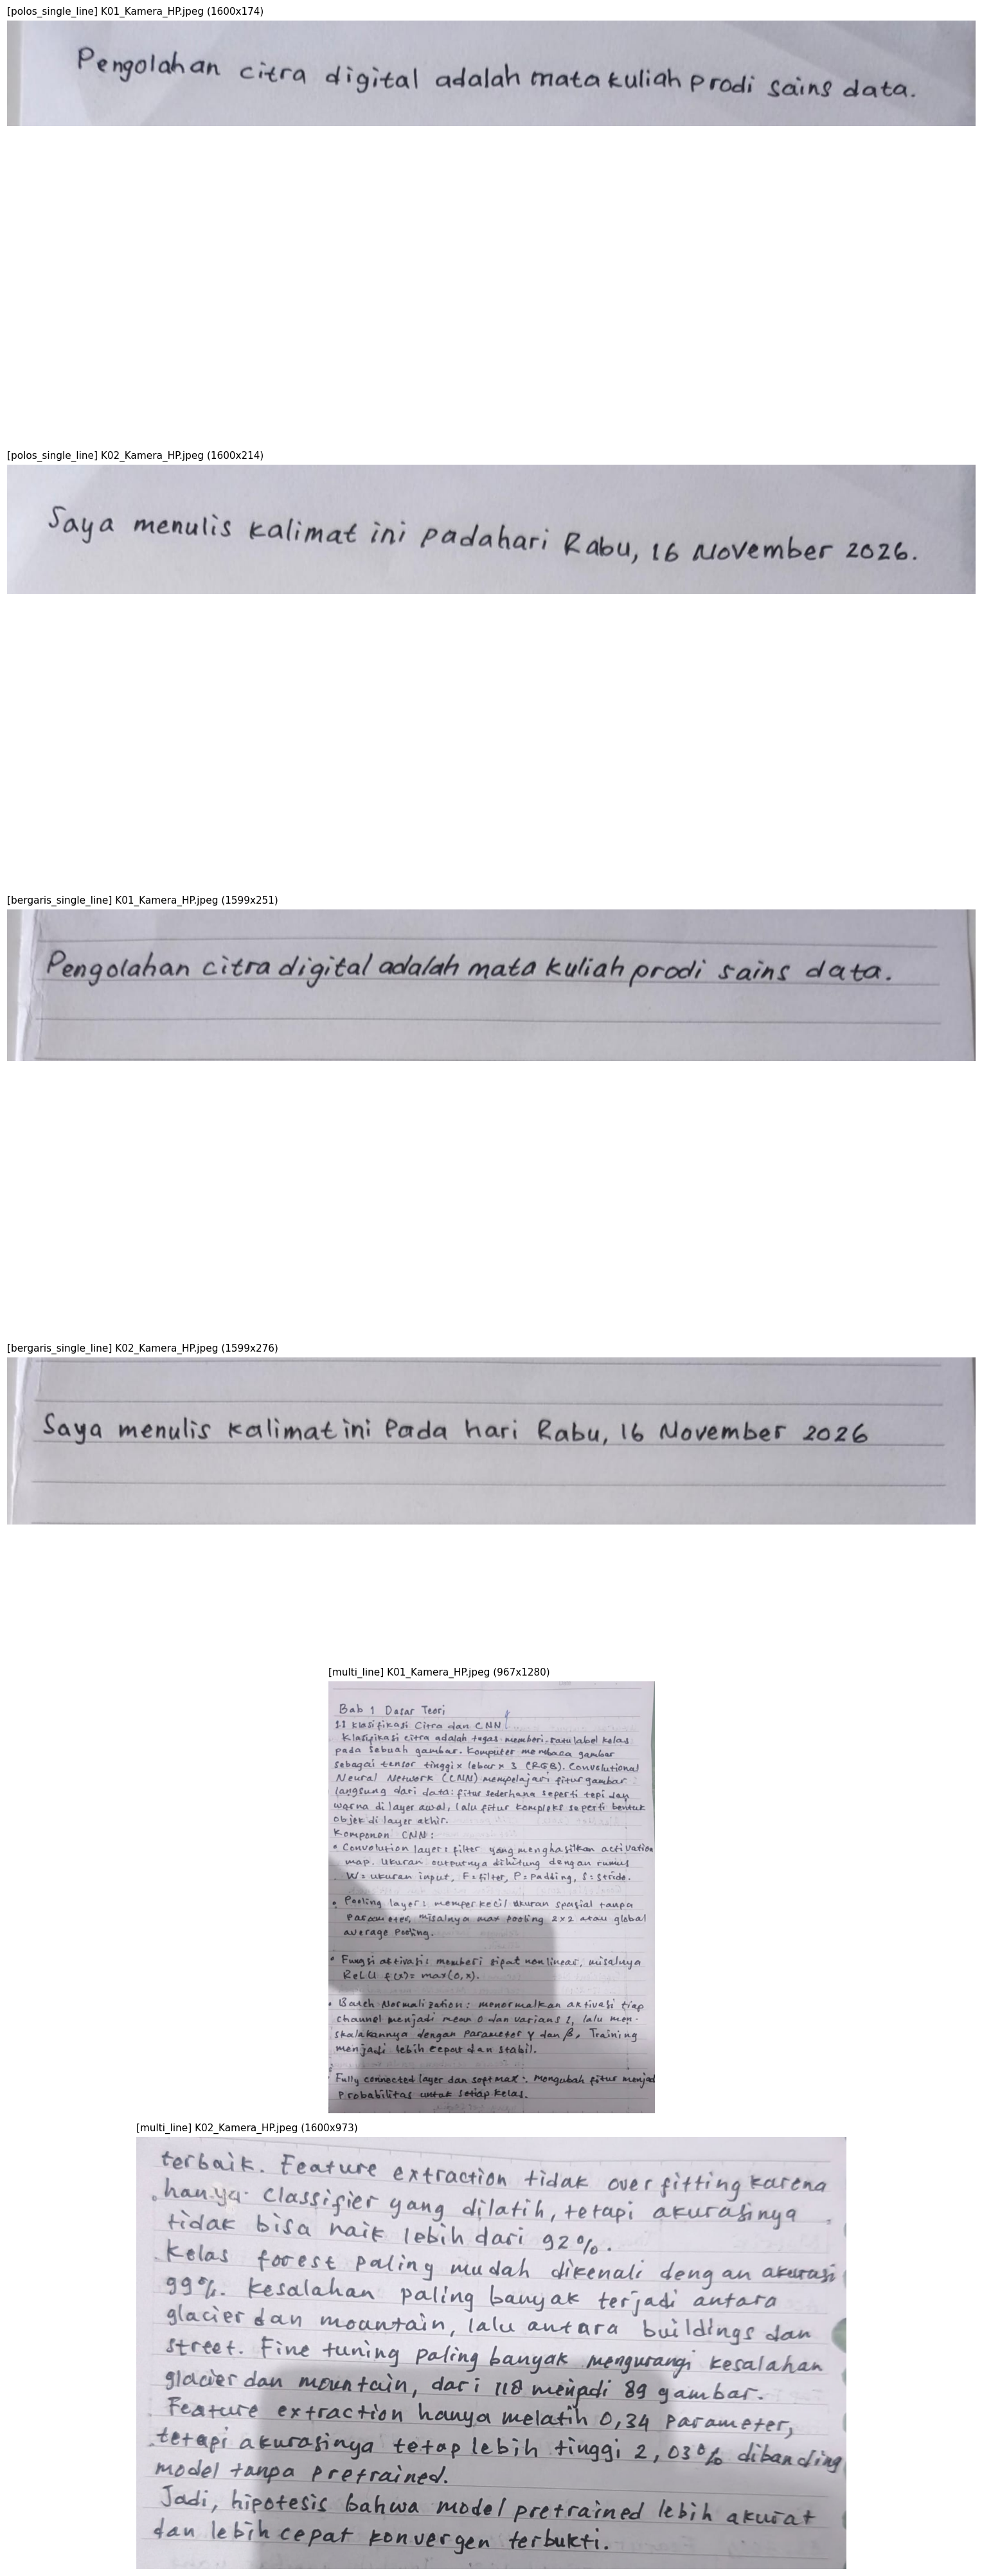

In [5]:
def tampil(citra_list, judul_list, ncols=1, lebar=14, cmap="gray"):
    n = len(citra_list)
    if n == 0:
        return
    nrows = int(np.ceil(n / ncols))
    tinggi_total = sum(c.shape[0] / c.shape[1] for c in citra_list[::ncols]) * lebar / ncols + 0.6 * nrows
    fig, axes = plt.subplots(nrows, ncols, figsize=(lebar, max(tinggi_total, 2.5)))
    axes = np.atleast_1d(axes).ravel()
    for ax, c, j in zip(axes, citra_list, judul_list):
        if c.ndim == 3:
            ax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(c, cmap=cmap, vmin=0, vmax=255)
        ax.set_title(j, fontsize=10, loc="left")
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

contoh = df.groupby("class_name").head(2)
tampil(list(contoh["citra"]), [f"[{r.class_name}] {r.file} ({r.lebar}x{r.tinggi})" for r in contoh.itertuples()])

## 2. Konversi Grayscale & Analisis Histogram

Selisih maks. rumus manual vs OpenCV: 0


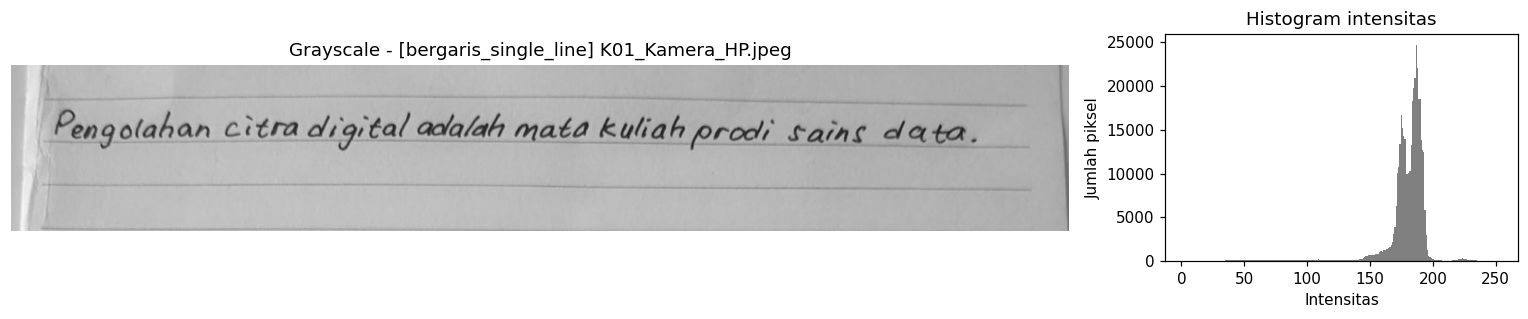

In [6]:
def ke_grayscale(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

df["gray"] = df["citra"].apply(ke_grayscale)

img0 = df.loc[0, "citra"].astype(np.float64)
B, G, R = img0[..., 0], img0[..., 1], img0[..., 2]
manual = np.round(0.299 * R + 0.587 * G + 0.114 * B).astype(np.uint8)
print("Selisih maks. rumus manual vs OpenCV:", np.abs(manual.astype(int) - df.loc[0, "gray"].astype(int)).max())

idx_contoh = df.index[df["has_lines"]][0] if df["has_lines"].any() else 0
fig, ax = plt.subplots(1, 2, figsize=(14, 3), gridspec_kw={"width_ratios": [3, 1]})
ax[0].imshow(df.loc[idx_contoh, "gray"], cmap="gray", vmin=0, vmax=255)
ax[0].set_title(f"Grayscale - [{df.loc[idx_contoh, 'class_name']}] {df.loc[idx_contoh, 'file']}")
ax[0].axis("off")
ax[1].hist(df.loc[idx_contoh, "gray"].ravel(), bins=256, range=(0, 255), color="gray")
ax[1].set_title("Histogram intensitas")
ax[1].set_xlabel("Intensitas")
ax[1].set_ylabel("Jumlah piksel")
plt.tight_layout()
plt.show()

## 3. Normalisasi Iluminasi

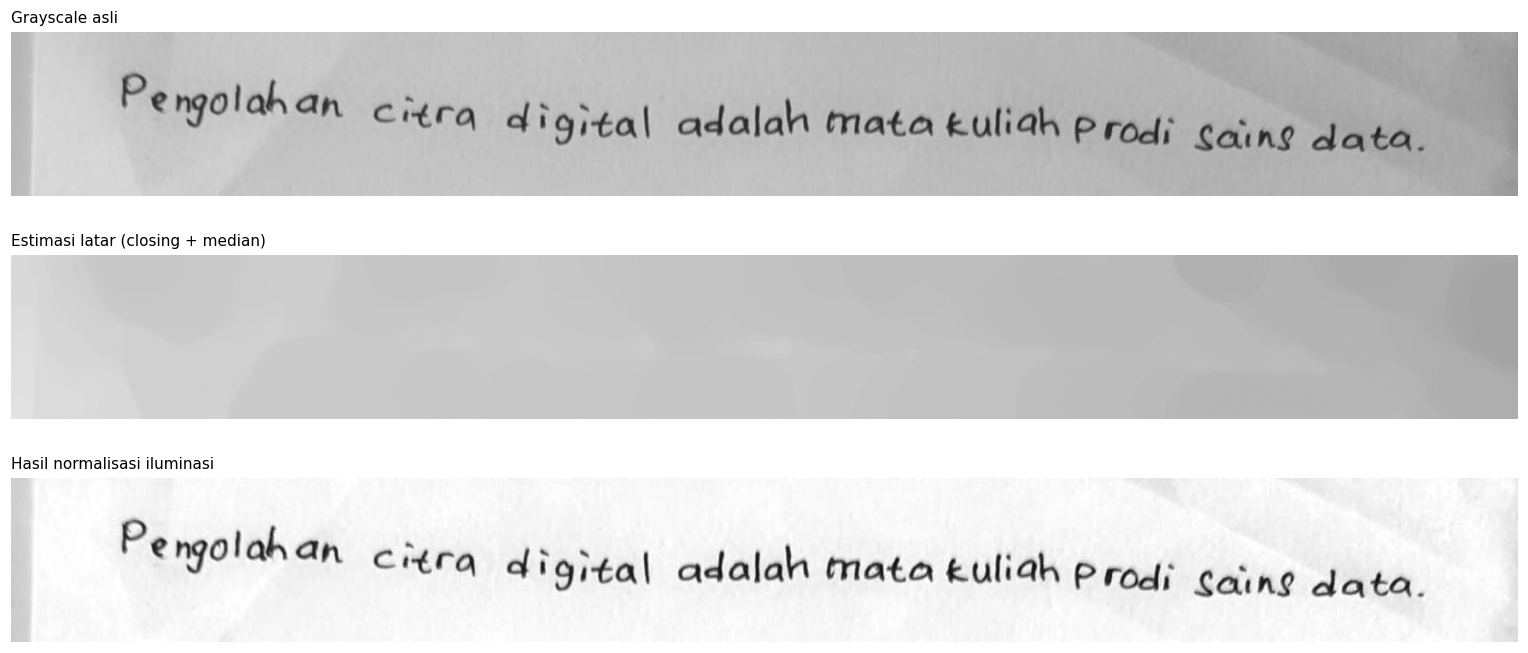

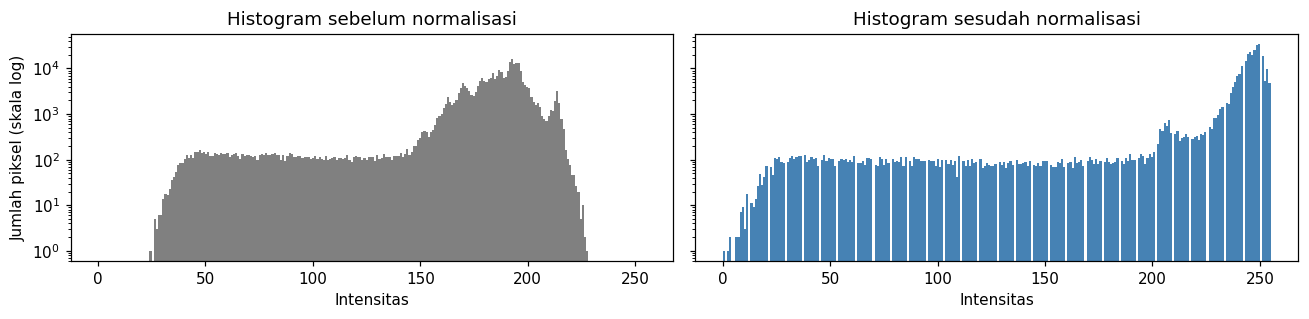

In [7]:
def normalisasi_iluminasi(gray, ukuran_kernel=None):
    # Ukuran kernel jauh lebih besar dari ketebalan goresan tinta, tetapi mengikuti variasi bayangan
    k = ukuran_kernel or (max(gray.shape) // 20) | 1  # pastikan ganjil
    k = max(k, 21)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    latar = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se)
    latar = cv2.medianBlur(latar, 21)
    norm = cv2.divide(gray, latar, scale=255)
    norm = cv2.normalize(norm, None, 0, 255, cv2.NORM_MINMAX)
    return norm, latar

hasil_norm = df["gray"].apply(normalisasi_iluminasi)
df["latar"] = hasil_norm.str[1]
df["norm"]  = hasil_norm.str[0]

i = df.index[0]
tampil(
    [df.loc[i, "gray"], df.loc[i, "latar"], df.loc[i, "norm"]],
    ["Grayscale asli", "Estimasi latar (closing + median)", "Hasil normalisasi iluminasi"]
)

fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
ax[0].hist(df.loc[i, "gray"].ravel(), bins=256, range=(0, 255), color="gray")
ax[0].set_title("Histogram sebelum normalisasi")
ax[1].hist(df.loc[i, "norm"].ravel(), bins=256, range=(0, 255), color="steelblue")
ax[1].set_title("Histogram sesudah normalisasi")
for a in ax:
    a.set_xlabel("Intensitas")
    a.set_yscale("log")
ax[0].set_ylabel("Jumlah piksel (skala log)")
plt.tight_layout()
plt.show()

## 4. Reduksi Noise (*Denoising*)

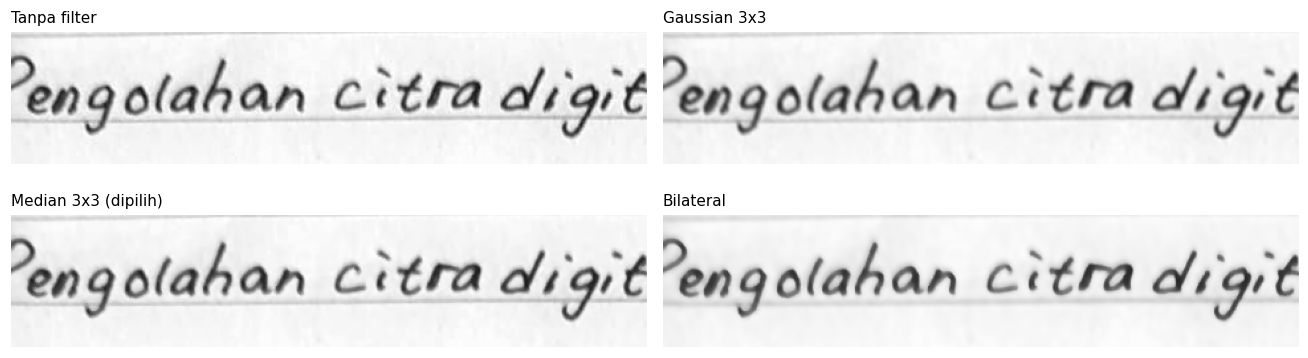

In [8]:
i = df.index[df["has_lines"]][0] if df["has_lines"].any() else 0
n = df.loc[i, "norm"]
gauss  = cv2.GaussianBlur(n, (3, 3), 0)
median = cv2.medianBlur(n, 3)
bilat  = cv2.bilateralFilter(n, 7, 50, 50)

h, w = n.shape
y0, y1, x0, x1 = int(h * 0.2), int(h * 0.6), int(w * 0.05), int(w * 0.35)
tampil(
    [n[y0:y1, x0:x1], gauss[y0:y1, x0:x1], median[y0:y1, x0:x1], bilat[y0:y1, x0:x1]],
    ["Tanpa filter", "Gaussian 3x3", "Median 3x3 (dipilih)", "Bilateral"],
    ncols=2, lebar=12
)

df["denoise"] = df["norm"].apply(lambda x: cv2.medianBlur(x, 3))

## 5. Binarisasi (Otsu vs. Adaptive Gaussian vs. Sauvola)

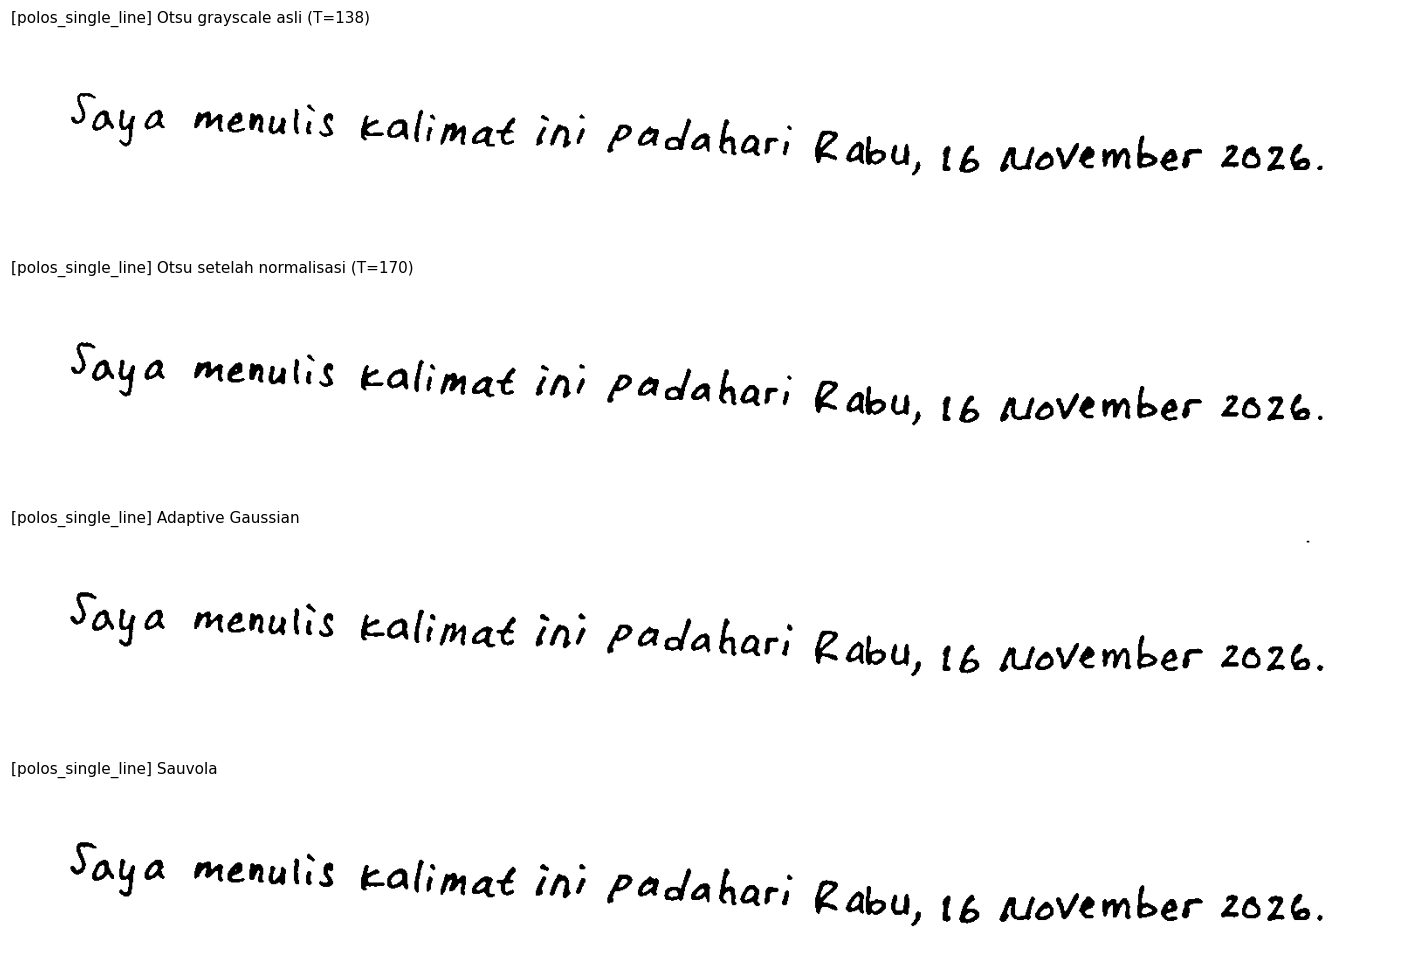

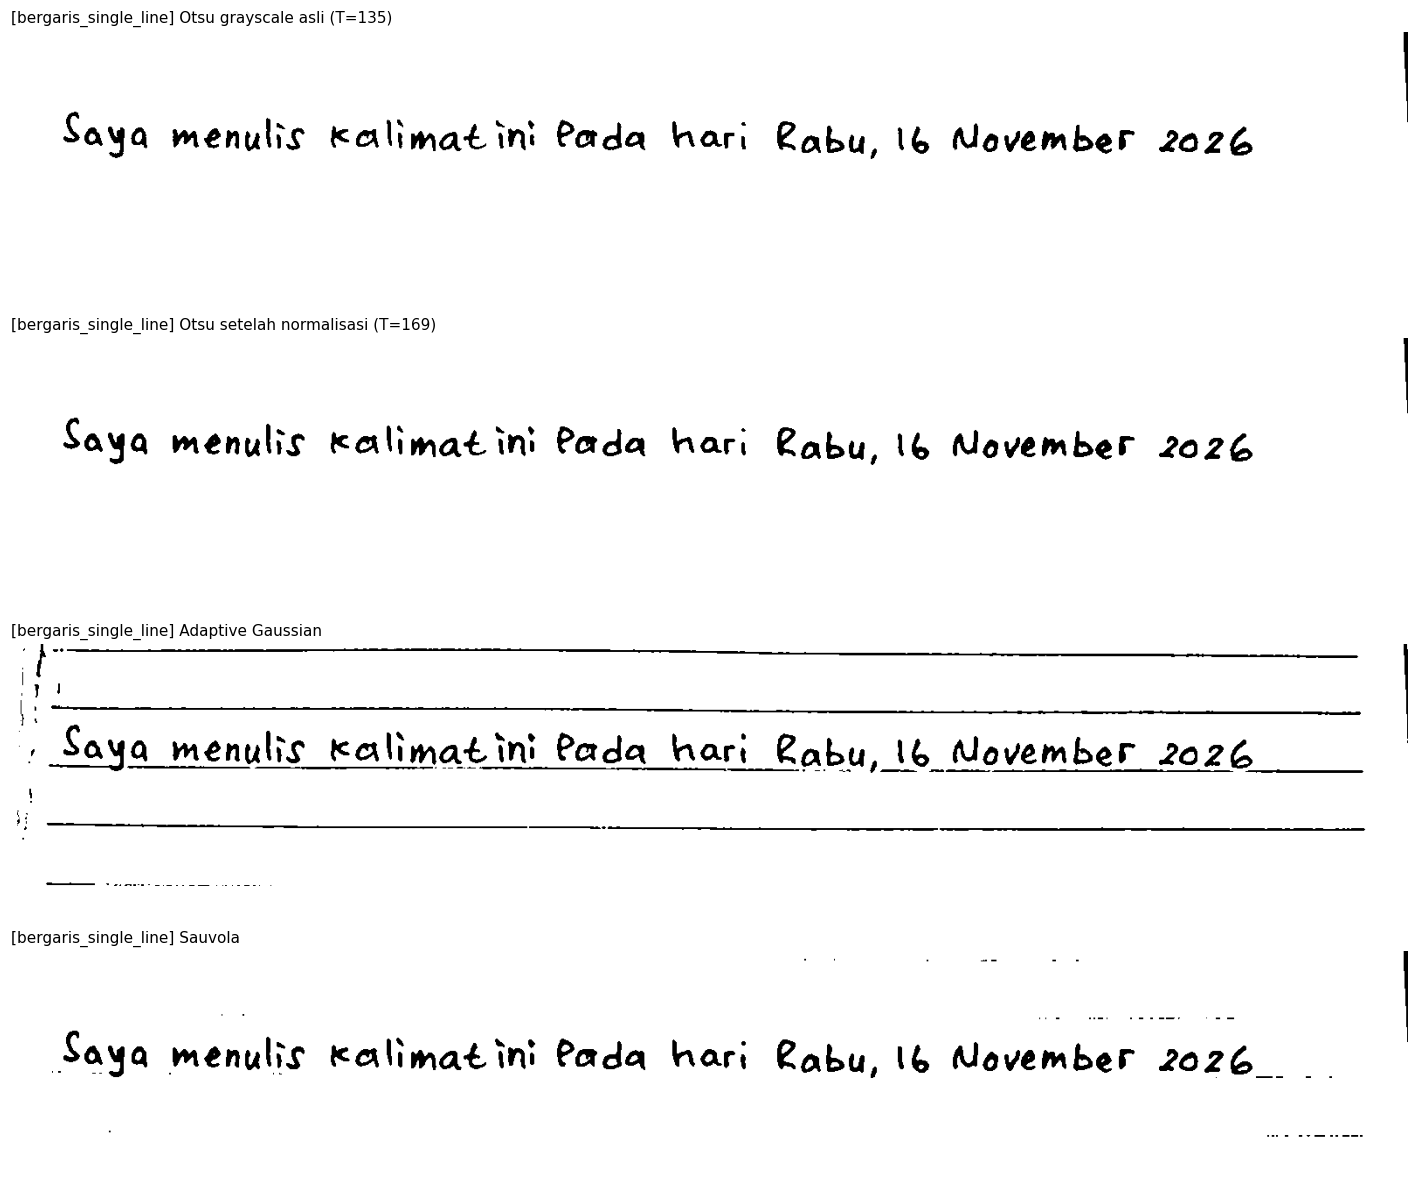

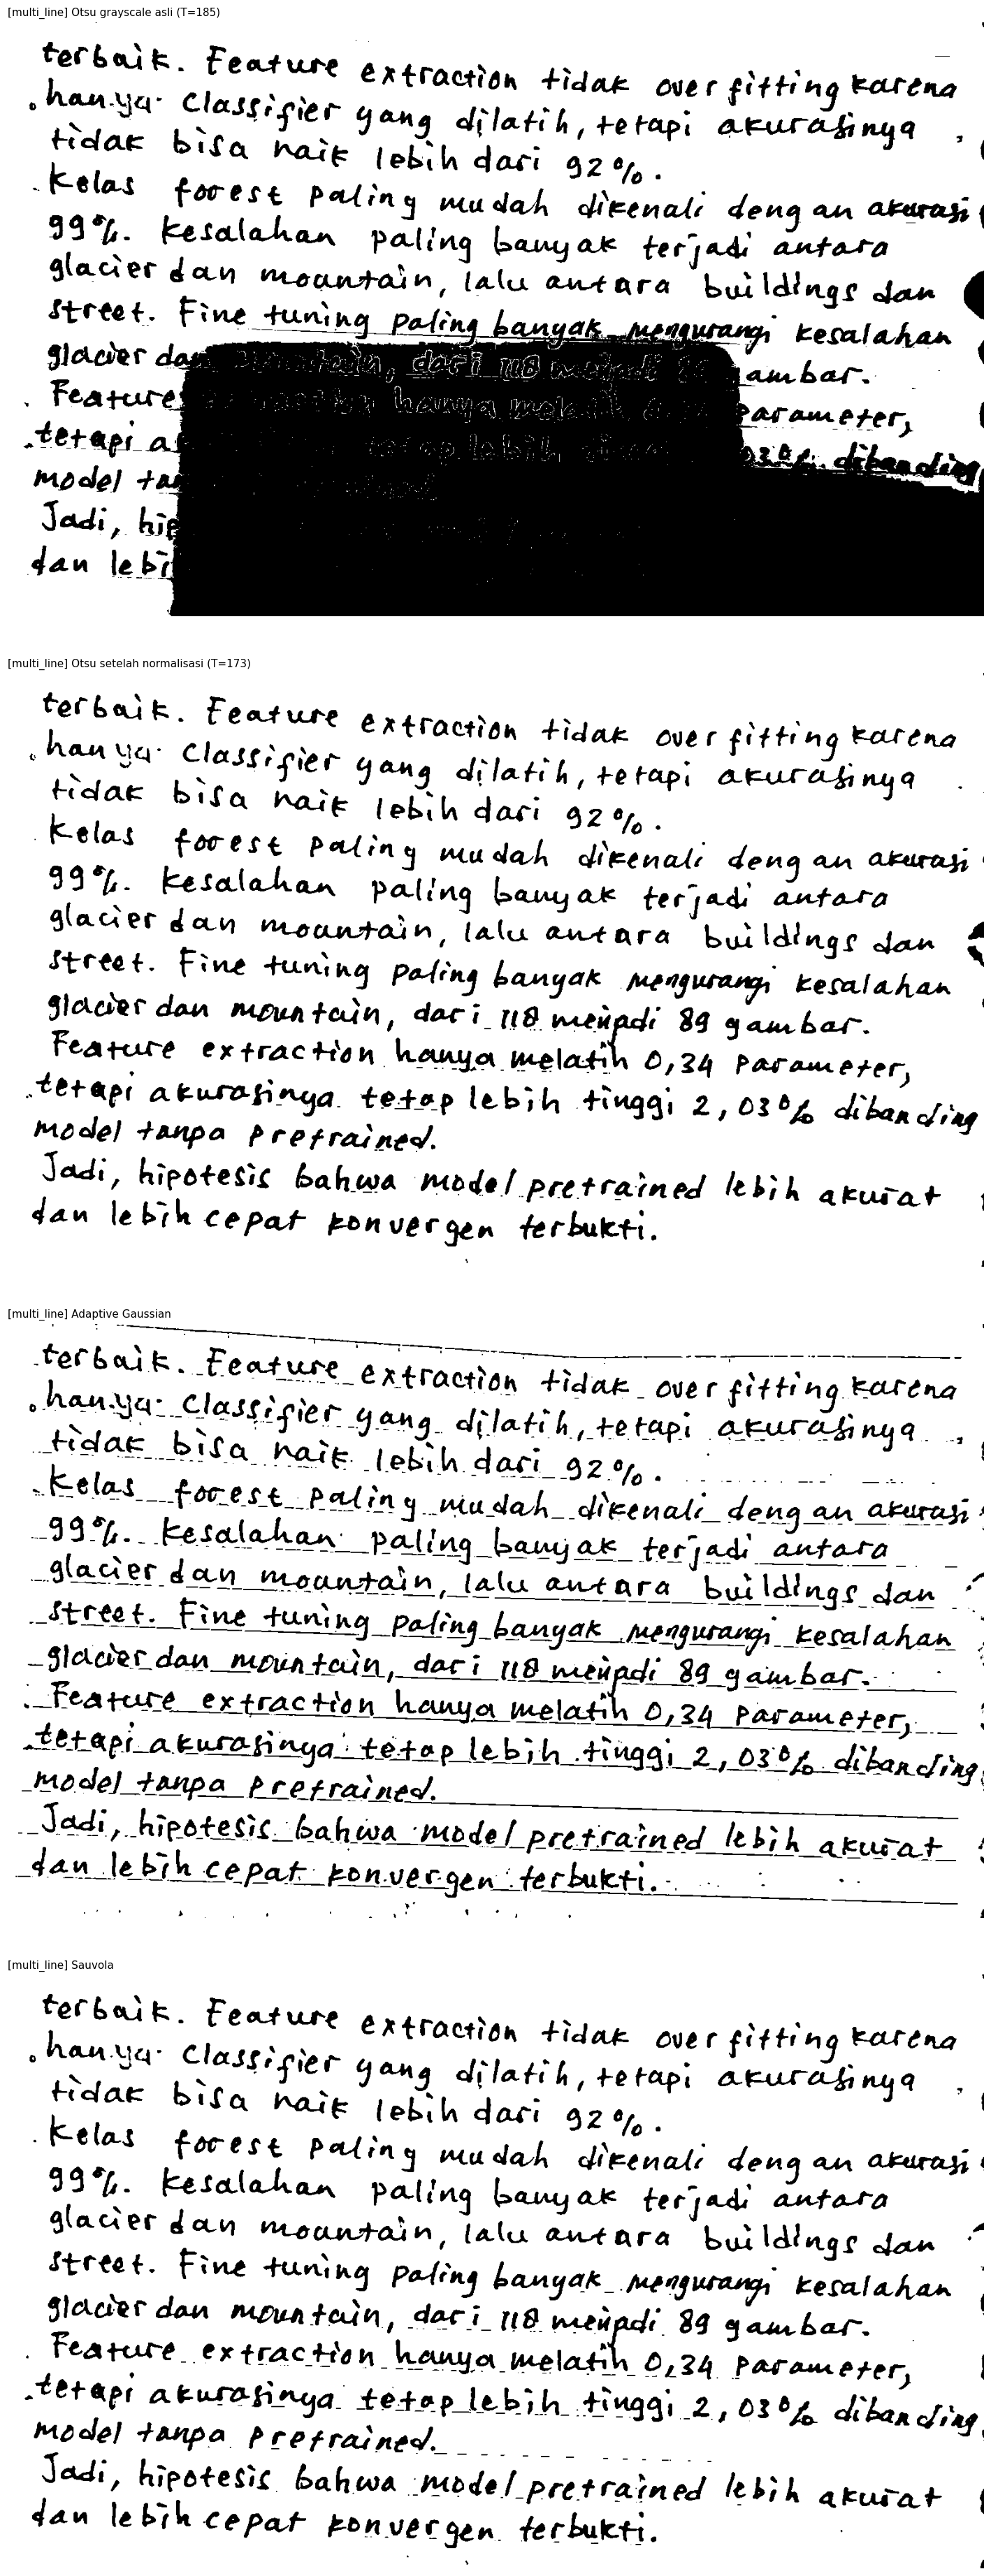

,image_id,class_name,ambang_otsu
0,polos_single_line_K01_01,polos_single_line,168.0
1,polos_single_line_K02_02,polos_single_line,170.0
2,polos_single_line_K03_03,polos_single_line,177.0
3,polos_single_line_K04_04,polos_single_line,173.0
4,polos_single_line_K05_05,polos_single_line,169.0
5,polos_single_line_K06_06,polos_single_line,170.0
6,polos_single_line_K07_07,polos_single_line,170.0
7,bergaris_single_line_K01_01,bergaris_single_line,170.0
8,bergaris_single_line_K02_02,bergaris_single_line,169.0
9,bergaris_single_line_K03_03,bergaris_single_line,170.0


In [9]:
def biner_otsu(gray):
    t, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return b, t

def biner_adaptive(gray, blok=31, C=15):
    return cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, blok, C
    )

def biner_sauvola(gray, window=31, k=0.2):
    thresh = threshold_sauvola(gray, window_size=window, k=k)
    return ((gray < thresh) * 255).astype(np.uint8)

for cls in df["class_name"].unique():
    sub_idx = df.index[df["class_name"] == cls]
    idx = sub_idx[min(1, len(sub_idx) - 1)]
    g, d = df.loc[idx, "gray"], df.loc[idx, "denoise"]
    b1, t1 = biner_otsu(g)
    b2, t2 = biner_otsu(d)
    tampil(
        [255 - b1, 255 - b2, 255 - biner_adaptive(d), 255 - biner_sauvola(d)],
        [
            f"[{cls}] Otsu grayscale asli (T={t1:.0f})",
            f"[{cls}] Otsu setelah normalisasi (T={t2:.0f})",
            f"[{cls}] Adaptive Gaussian",
            f"[{cls}] Sauvola",
        ],
        lebar=13,
    )

# Gunakan Otsu setelah normalisasi iluminasi sebagai representasi biner utama (atau Sauvola untuk multi_line)
def binarisasi_adaptif_kelas(row):
    if row["layout_type"] == "multi_line":
        # Sauvola menjaga ketebalan tinta tipis pada foto halaman penuh
        b = biner_sauvola(row["denoise"], window=31, k=0.2)
        _, t = biner_otsu(row["denoise"])
        return b, t
    return biner_otsu(row["denoise"])

hasil_biner = df.apply(binarisasi_adaptif_kelas, axis=1)
df["biner"]       = hasil_biner.str[0]
df["ambang_otsu"] = hasil_biner.str[1]
df[["image_id", "class_name", "ambang_otsu"]]

## 6. Penghapusan Garis Buku Kondisional

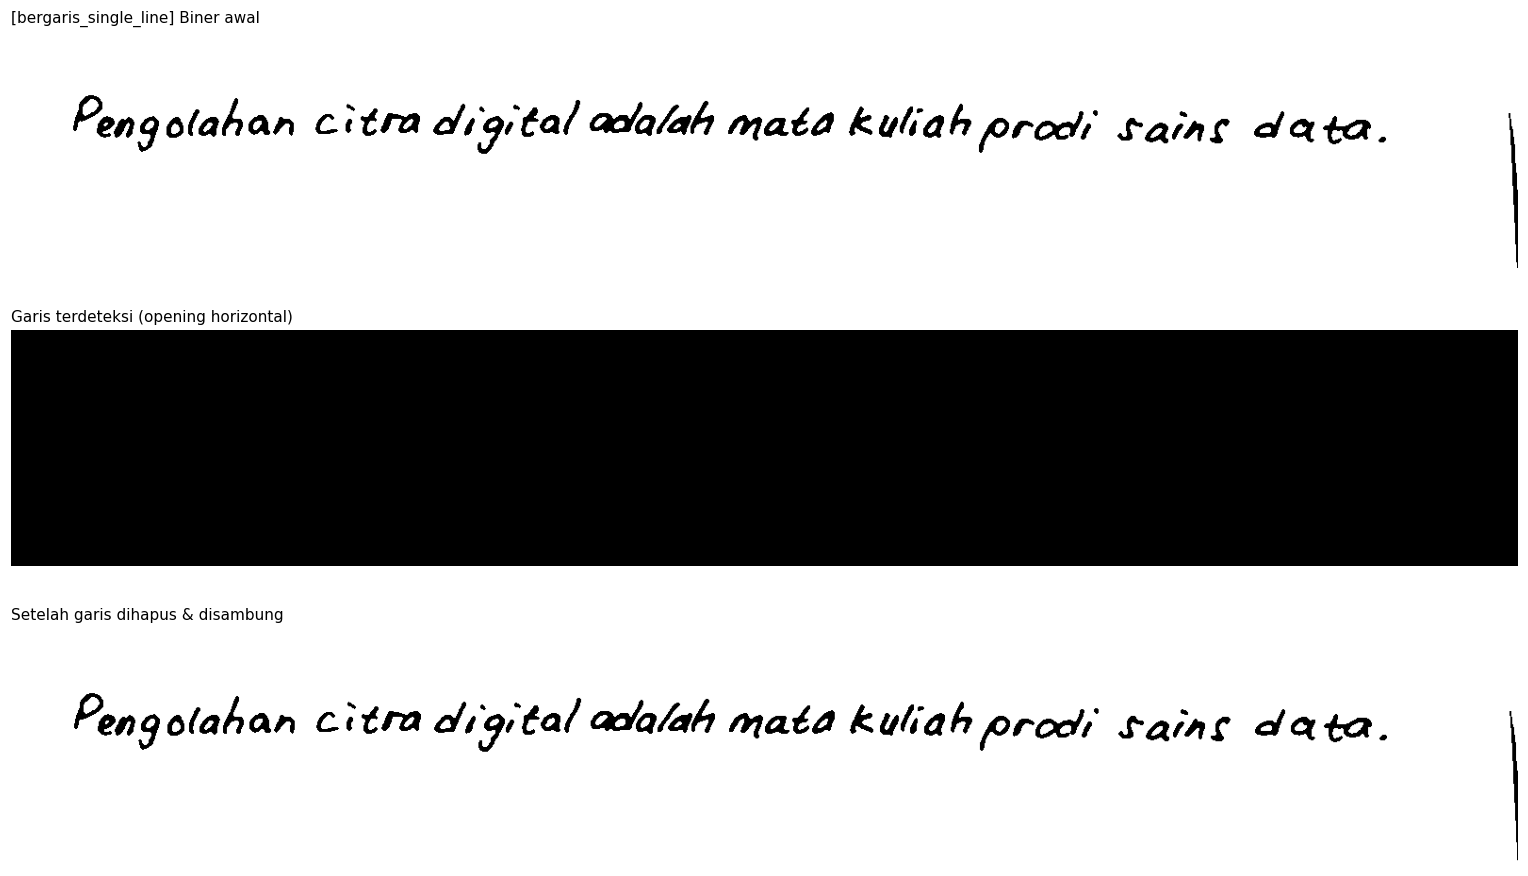

,count,mean,min,max
class_name,,,,
bergaris_single_line,7.0,0.0,0.0,0.0
multi_line,10.0,4487.1,0.0,44871.0
polos_single_line,7.0,0.0,0.0,0.0


In [10]:
def hapus_garis_horizontal(biner, has_lines=True, rasio=15):
    if not has_lines:
        return biner.copy(), np.zeros_like(biner)
    panjang = max(biner.shape[1] // rasio, 25)
    se_garis = cv2.getStructuringElement(cv2.MORPH_RECT, (panjang, 1))
    garis = cv2.morphologyEx(biner, cv2.MORPH_OPEN, se_garis, iterations=1)
    tanpa_garis = cv2.subtract(biner, garis)
    # Sambung kembali goresan huruf yang terputus pada titik persilangan garis
    se_sambung = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    tanpa_garis = cv2.morphologyEx(tanpa_garis, cv2.MORPH_CLOSE, se_sambung)
    return tanpa_garis, garis

hasil_garis = df.apply(lambda r: hapus_garis_horizontal(r["biner"], r["has_lines"]), axis=1)
df["tanpa_garis"]      = hasil_garis.str[0]
df["garis"]            = hasil_garis.str[1]
df["px_garis_dihapus"] = df["garis"].apply(lambda g: int((g > 0).sum()))

if df["has_lines"].any():
    i = df.index[df["has_lines"]][0]
    tampil(
        [255 - df.loc[i, "biner"], df.loc[i, "garis"], 255 - df.loc[i, "tanpa_garis"]],
        [
            f"[{df.loc[i, 'class_name']}] Biner awal",
            "Garis terdeteksi (opening horizontal)",
            "Setelah garis dihapus & disambung",
        ],
    )

df.groupby("class_name")["px_garis_dihapus"].describe()[["count", "mean", "min", "max"]]

## 7. Pembersihan Komponen Terhubung (*Connected Component Filtering*)


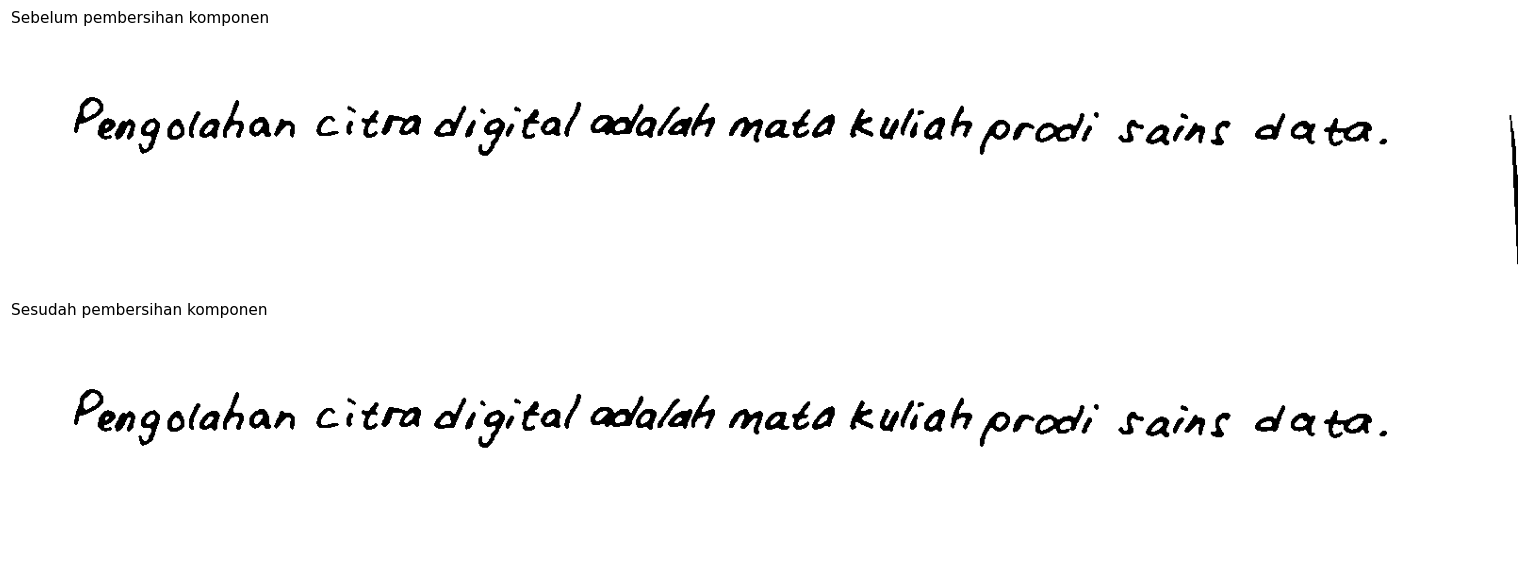

,image_id,class_name,buang_kecil,buang_sisa_garis,buang_tepi
0,polos_single_line_K01_01,polos_single_line,0,0,0
1,polos_single_line_K02_02,polos_single_line,0,0,0
2,polos_single_line_K03_03,polos_single_line,0,0,0
3,polos_single_line_K04_04,polos_single_line,0,0,0
4,polos_single_line_K05_05,polos_single_line,0,0,0
5,polos_single_line_K06_06,polos_single_line,0,0,0
6,polos_single_line_K07_07,polos_single_line,0,0,0
7,bergaris_single_line_K01_01,bergaris_single_line,0,0,1
8,bergaris_single_line_K02_02,bergaris_single_line,0,0,1
9,bergaris_single_line_K03_03,bergaris_single_line,0,0,0


In [11]:
def bersihkan_komponen(biner, layout_type="single_line", luas_min=8):
    H, W = biner.shape
    n, label, stats, _ = cv2.connectedComponentsWithStats(biner, connectivity=8)
    simpan = np.zeros(n, dtype=bool)
    alasan = {"kecil": 0, "sisa_garis": 0, "tepi": 0}
    batas_lebar_tepi = 0.35 * W if layout_type == "multi_line" else 0.5 * W

    for k in range(1, n):
        x, y, w, h, luas = stats[k]
        menyentuh_tepi = x == 0 or y == 0 or (x + w >= W) or (y + h >= H)
        if luas < luas_min:
            alasan["kecil"] += 1
            continue
        if h <= 4 and w >= 3 * h and w > 8:
            alasan["sisa_garis"] += 1
            continue
        if menyentuh_tepi and (w >= batas_lebar_tepi or h <= 3 or (h >= 0.2 * H and w <= 0.02 * W)):
            alasan["tepi"] += 1
            continue
        simpan[k] = True
    return np.where(simpan[label], 255, 0).astype(np.uint8), alasan

hasil_cc = df.apply(lambda r: bersihkan_komponen(r["tanpa_garis"], r["layout_type"]), axis=1)
df["bersih"] = hasil_cc.str[0]
df = pd.concat([df, pd.DataFrame(list(hasil_cc.str[1]), index=df.index).add_prefix("buang_")], axis=1)

i = df.index[df["has_lines"]][0] if df["has_lines"].any() else 0
tampil(
    [255 - df.loc[i, "tanpa_garis"], 255 - df.loc[i, "bersih"]],
    ["Sebelum pembersihan komponen", "Sesudah pembersihan komponen"]
)
df[["image_id", "class_name", "buang_kecil", "buang_sisa_garis", "buang_tepi"]]

## 8. Koreksi Kemiringan (*Deskewing*)


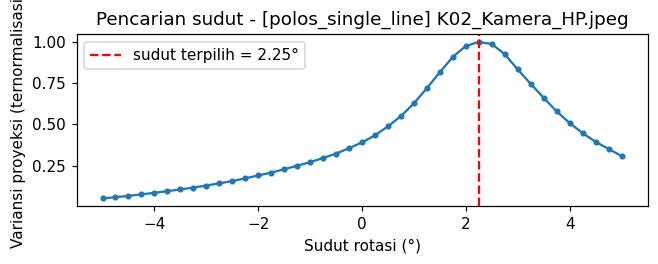

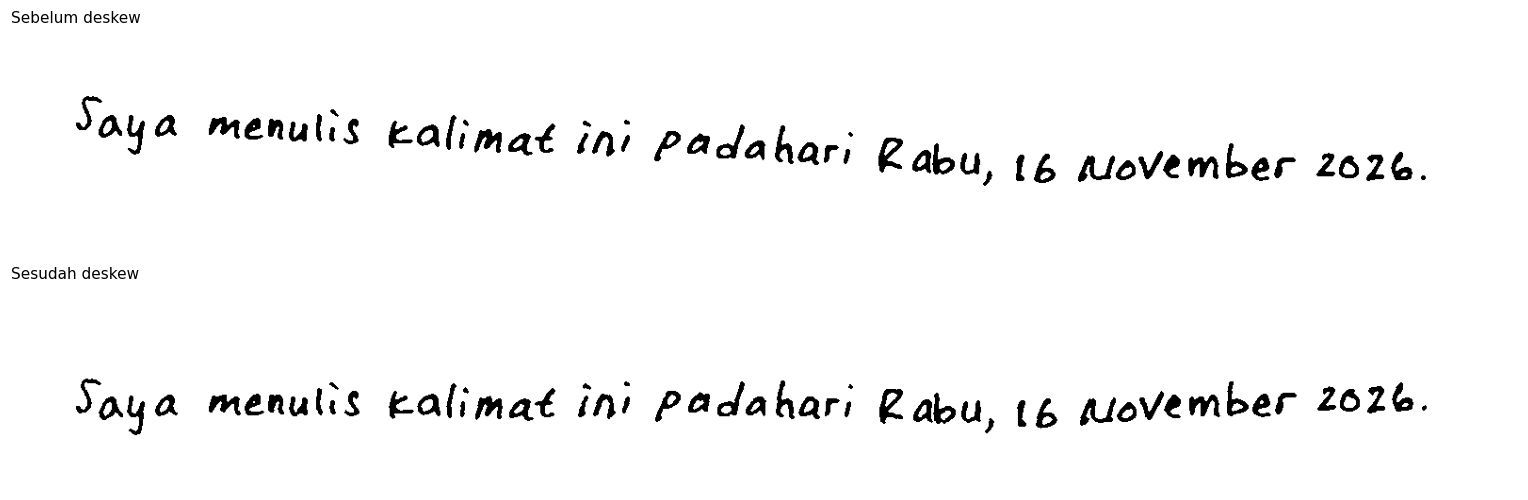

,image_id,class_name,sudut_deskew
0,polos_single_line_K01_01,polos_single_line,1.75
1,polos_single_line_K02_02,polos_single_line,2.25
2,polos_single_line_K03_03,polos_single_line,1.00
3,polos_single_line_K04_04,polos_single_line,0.75
4,polos_single_line_K05_05,polos_single_line,-1.25
5,polos_single_line_K06_06,polos_single_line,1.75
6,polos_single_line_K07_07,polos_single_line,0.00
7,bergaris_single_line_K01_01,bergaris_single_line,0.25
8,bergaris_single_line_K02_02,bergaris_single_line,0.25
9,bergaris_single_line_K03_03,bergaris_single_line,0.00


In [12]:
def putar(citra, sudut):
    h, w = citra.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, 1.0)
    return cv2.warpAffine(citra, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)

def estimasi_sudut(biner, rentang=5, langkah=0.25):
    sudut_list = np.arange(-rentang, rentang + 1e-9, langkah)
    skor = [np.var(putar(biner, a).sum(axis=1, dtype=np.float64)) for a in sudut_list]
    return float(sudut_list[int(np.argmax(skor))]), sudut_list, np.array(skor)

hasil_deskew = df["bersih"].apply(estimasi_sudut)
df["sudut_deskew"] = hasil_deskew.str[0]
df["lurus"] = [putar(b, a) for b, a in zip(df["bersih"], df["sudut_deskew"])]

i = df["sudut_deskew"].abs().idxmax()
_, sl, sk = hasil_deskew[i]
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(sl, sk / max(sk.max(), 1e-9), marker="o", ms=3)
ax.axvline(df.loc[i, "sudut_deskew"], color="red", ls="--", label=f"sudut terpilih = {df.loc[i, 'sudut_deskew']}°")
ax.set_xlabel("Sudut rotasi (°)")
ax.set_ylabel("Variansi proyeksi (ternormalisasi)")
ax.set_title(f"Pencarian sudut - [{df.loc[i, 'class_name']}] {df.loc[i, 'file']}")
ax.legend()
plt.tight_layout()
plt.show()

tampil([255 - df.loc[i, "bersih"], 255 - df.loc[i, "lurus"]], ["Sebelum deskew", "Sesudah deskew"])
df[["image_id", "class_name", "sudut_deskew"]]

## 9. Segmentasi Baris Viterbi Kondisional (`layout_type == 'multi_line'`)

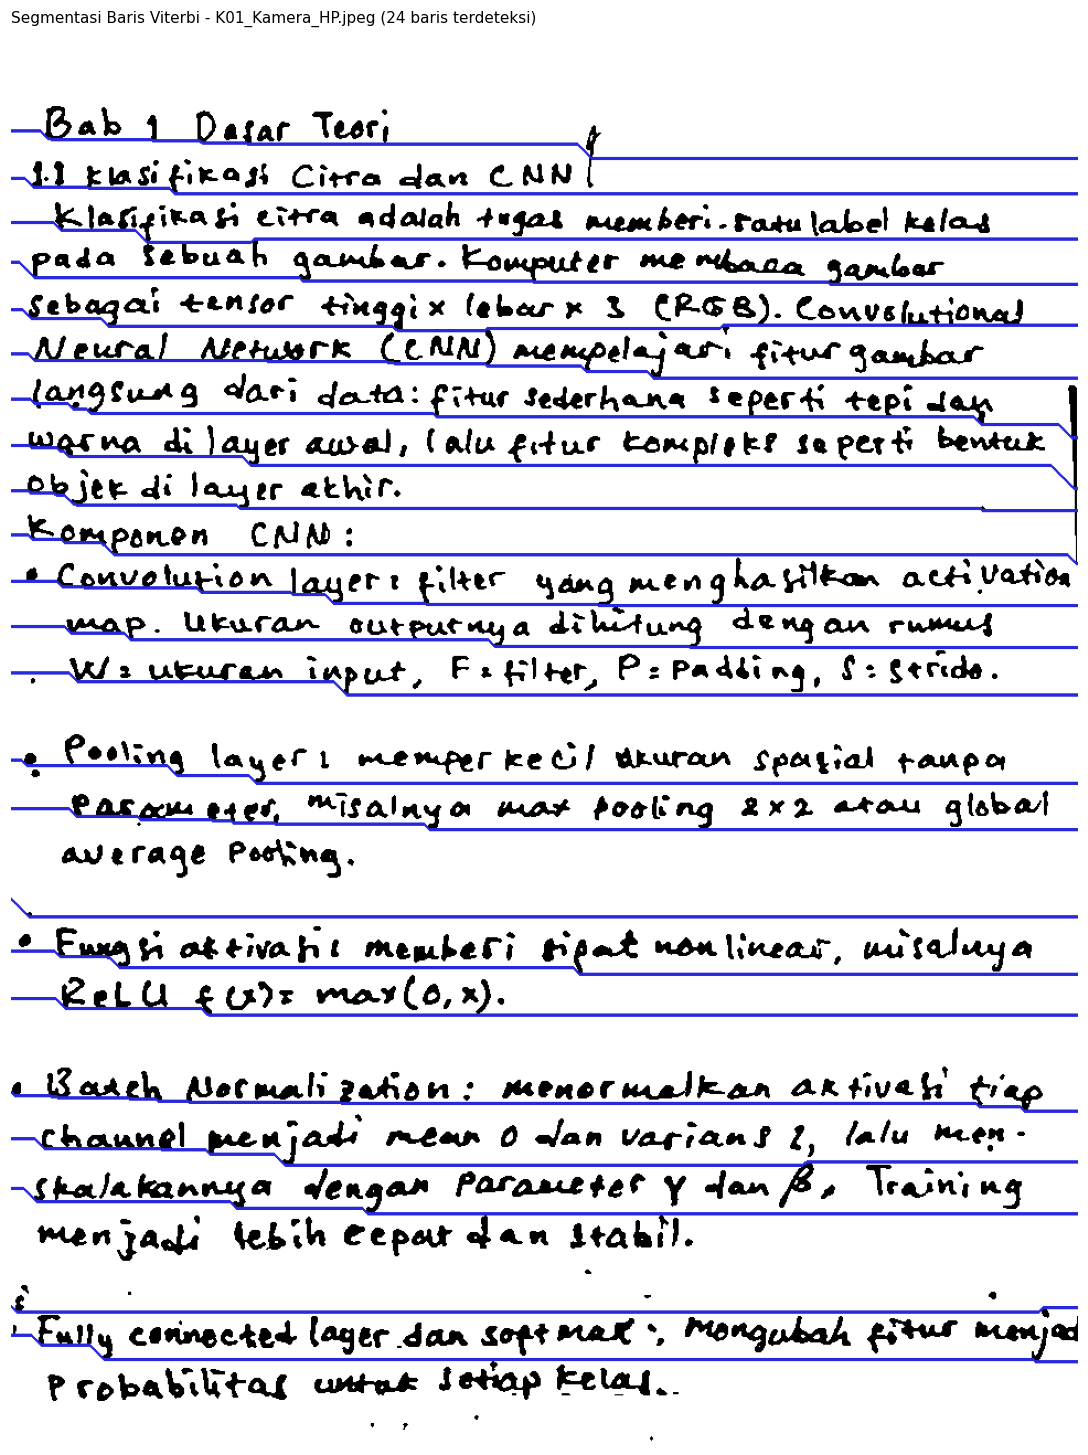

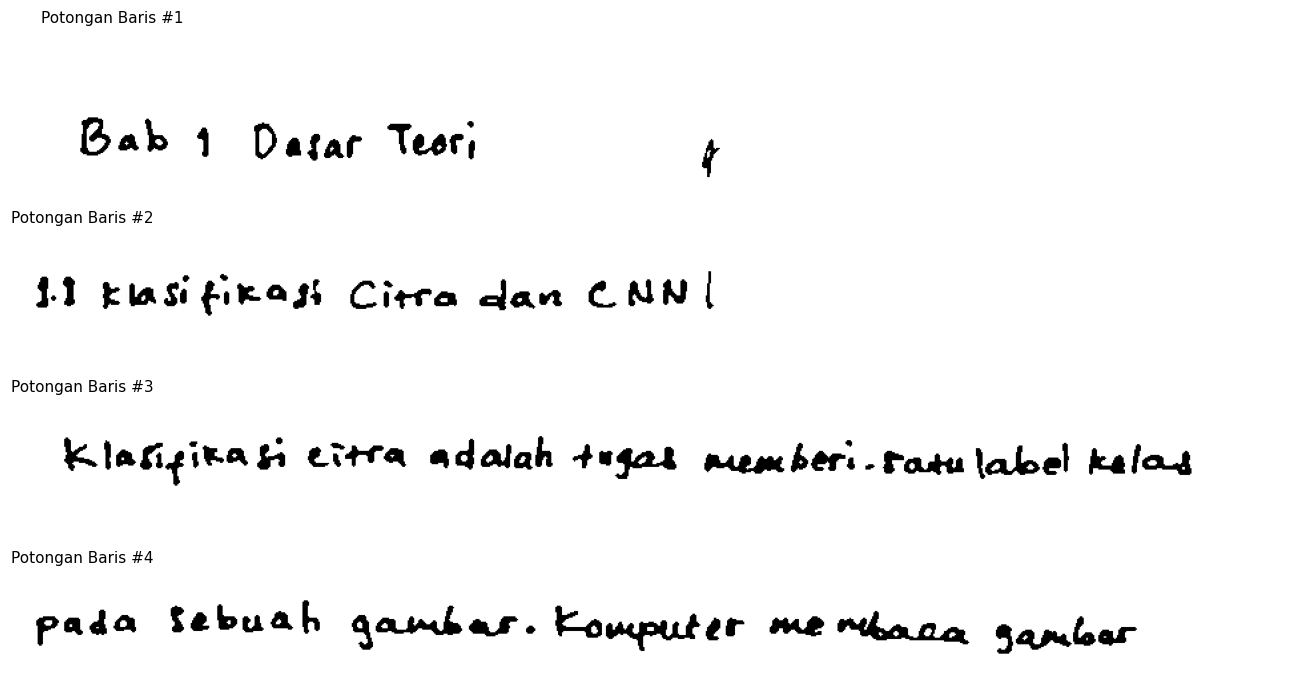

,image_id,class_name,layout_type,jumlah_baris
0,polos_single_line_K01_01,polos_single_line,single_line,1
1,polos_single_line_K02_02,polos_single_line,single_line,1
2,polos_single_line_K03_03,polos_single_line,single_line,1
3,polos_single_line_K04_04,polos_single_line,single_line,1
4,polos_single_line_K05_05,polos_single_line,single_line,1
5,polos_single_line_K06_06,polos_single_line,single_line,1
6,polos_single_line_K07_07,polos_single_line,single_line,1
7,bergaris_single_line_K01_01,bergaris_single_line,single_line,1
8,bergaris_single_line_K02_02,bergaris_single_line,single_line,1
9,bergaris_single_line_K03_03,bergaris_single_line,single_line,1


In [13]:
def segmentasi_baris_viterbi(biner, min_jarak_baris=35, ambang_puncak=0.18, margin_y=6):
    """Memecah citra biner multi-baris (tinta=255, latar=0) menjadi daftar potongan citra 1 baris
    menggunakan pencarian lembah antar-baris & jalur biaya minimum (Viterbi seam)."""
    H, W = biner.shape
    # 1. Hitung profil proyeksi horizontal dan haluskan dengan filter Gaussian 1D
    proj = biner.sum(axis=1, dtype=np.float64)
    k_smooth = max(int(H // 80) | 1, 9)
    proj_halus = cv2.GaussianBlur(proj.reshape(-1, 1), (1, k_smooth), 0).ravel()
    if proj_halus.max() == 0:
        return [biner], []

    proj_norm = proj_halus / proj_halus.max()

    # 2. Deteksi pusat setiap baris teks (local maxima di atas ambang_puncak)
    puncak = []
    for y in range(1, H - 1):
        if proj_norm[y] >= ambang_puncak and proj_norm[y] >= proj_norm[y - 1] and proj_norm[y] >= proj_norm[y + 1]:
            if not puncak or (y - puncak[-1]) >= min_jarak_baris:
                puncak.append(y)
            elif proj_norm[y] > proj_norm[puncak[-1]]:
                puncak[-1] = y

    if len(puncak) <= 1:
        return [biner], []

    # 3. Cari jalur pemisah (seam) berbiaya minimum (Viterbi) di antara setiap pasang puncak baris
    # Biaya piksel tinggi jika mengenai tinta (biner > 0), rendah jika melewati ruang kosong
    cost_map = (biner > 0).astype(np.float32) * 10.0 + 0.1
    jalur_pemisah = []

    for y_atas, y_bawah in zip(puncak[:-1], puncak[1:]):
        band = cost_map[y_atas:y_bawah + 1, :]
        bh, bw = band.shape
        dp = np.zeros_like(band)
        backptr = np.zeros((bh, bw), dtype=np.int32)
        dp[:, 0] = band[:, 0]

        for x in range(1, bw):
            for r in range(bh):
                r_min = max(0, r - 1)
                r_max = min(bh, r + 2)
                sub = dp[r_min:r_max, x - 1]
                best_offset = int(np.argmin(sub))
                best_r = r_min + best_offset
                dp[r, x] = band[r, x] + dp[best_r, x - 1] + (0.05 if best_r != r else 0.0)
                backptr[r, x] = best_r

        # Backtracking jalur biaya minimum dari kolom terakhir ke kolom pertama
        seam = np.zeros(bw, dtype=np.int32)
        seam[-1] = int(np.argmin(dp[:, -1]))
        for x in range(bw - 2, -1, -1):
            seam[x] = backptr[seam[x + 1], x + 1]
        jalur_pemisah.append(seam + y_atas)

    # 4. Potong tiap baris mengikuti jalur pemisah Viterbi
    potongan_baris = []
    batas_atas = np.zeros(W, dtype=np.int32)
    semua_batas = jalur_pemisah + [np.full(W, H - 1, dtype=np.int32)]

    for batas_bawah in semua_batas:
        y0 = max(0, int(batas_atas.min()) - margin_y)
        y1 = min(H, int(batas_bawah.max()) + margin_y + 1)
        mask_baris = np.zeros((y1 - y0, W), dtype=np.uint8)
        for x in range(W):
            r0 = max(y0, int(batas_atas[x])) - y0
            r1 = min(y1, int(batas_bawah[x]) + 1) - y0
            if r1 > r0:
                mask_baris[r0:r1, x] = biner[y0 + r0:y0 + r1, x]
        if (mask_baris > 0).sum() > 25:
            potongan_baris.append(mask_baris)
        batas_atas = batas_bawah

    return potongan_baris if potongan_baris else [biner], jalur_pemisah

def jalankan_segmentasi_kondisional(row):
    if row["layout_type"] == "multi_line":
        return segmentasi_baris_viterbi(row["lurus"])
    return [row["lurus"]], []

hasil_seg = df.apply(jalankan_segmentasi_kondisional, axis=1)
df["baris_tersegmentasi"] = hasil_seg.str[0]
df["jalur_viterbi"]       = hasil_seg.str[1]
df["jumlah_baris"]        = df["baris_tersegmentasi"].apply(len)

# Visualisasi hasil segmentasi Viterbi pada Kelas 3 (multi_line) jika ada
if (df["layout_type"] == "multi_line").any():
    idx_m = df.index[df["layout_type"] == "multi_line"][0]
    vis_seg = cv2.cvtColor(255 - df.loc[idx_m, "lurus"], cv2.COLOR_GRAY2RGB)
    for seam in df.loc[idx_m, "jalur_viterbi"]:
        for x, y in enumerate(seam):
            cv2.circle(vis_seg, (x, int(y)), 1, (220, 40, 40), -1)
    tampil(
        [vis_seg],
        [f"Segmentasi Baris Viterbi - {df.loc[idx_m, 'file']} ({df.loc[idx_m, 'jumlah_baris']} baris terdeteksi)"],
        lebar=10,
    )
    contoh_baris = df.loc[idx_m, "baris_tersegmentasi"][:4]
    tampil(
        [255 - b for b in contoh_baris],
        [f"Potongan Baris #{k+1}" for k in range(len(contoh_baris))],
        lebar=12,
    )

df[["image_id", "class_name", "layout_type", "jumlah_baris"]]

## 10. Cropping, Padding Margin Putih, & Penyimpanan Citra Hasil


In [14]:
def crop_padding(biner, pad=25):
    ys, xs = np.where(biner > 0)
    if len(xs) == 0:
        return 255 - biner
    potong = biner[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    potong = cv2.copyMakeBorder(potong, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
    return 255 - potong  # tinta hitam (0), latar putih (255)

df["final_lines"] = df["baris_tersegmentasi"].apply(lambda lst: [crop_padding(b, pad=25) for b in lst])
df["final"]       = df["final_lines"].apply(lambda lst: lst[0])

for r in df.itertuples():
    folder_cls = OUT_DIR / r.class_name
    folder_cls.mkdir(parents=True, exist_ok=True)
    paths_baris = []
    for idx_b, img_line in enumerate(r.final_lines, start=1):
        nama_out = f"{r.kode}.png" if len(r.final_lines) == 1 else f"{r.kode}_baris{idx_b:02d}.png"
        out_file = folder_cls / nama_out
        cv2.imwrite(str(out_file), img_line)
        paths_baris.append(str(out_file))
    df.loc[r.Index, "path_hasil"] = paths_baris[0]

print("Seluruh citra hasil pra-pemrosesan tersimpan di:", OUT_DIR.resolve())
df[["image_id", "class_name", "jumlah_baris", "path_hasil"]]

Seluruh citra hasil pra-pemrosesan tersimpan di: /content/drive/MyDrive/Semester 7/PCD/hasil_prapemrosesan


,image_id,class_name,jumlah_baris,path_hasil
0,polos_single_line_K01_01,polos_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
1,polos_single_line_K02_02,polos_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
2,polos_single_line_K03_03,polos_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
3,polos_single_line_K04_04,polos_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
4,polos_single_line_K05_05,polos_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
5,polos_single_line_K06_06,polos_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
6,polos_single_line_K07_07,polos_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
7,bergaris_single_line_K01_01,bergaris_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
8,bergaris_single_line_K02_02,bergaris_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
9,bergaris_single_line_K03_03,bergaris_single_line,1,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...


=== polos_single_line ===


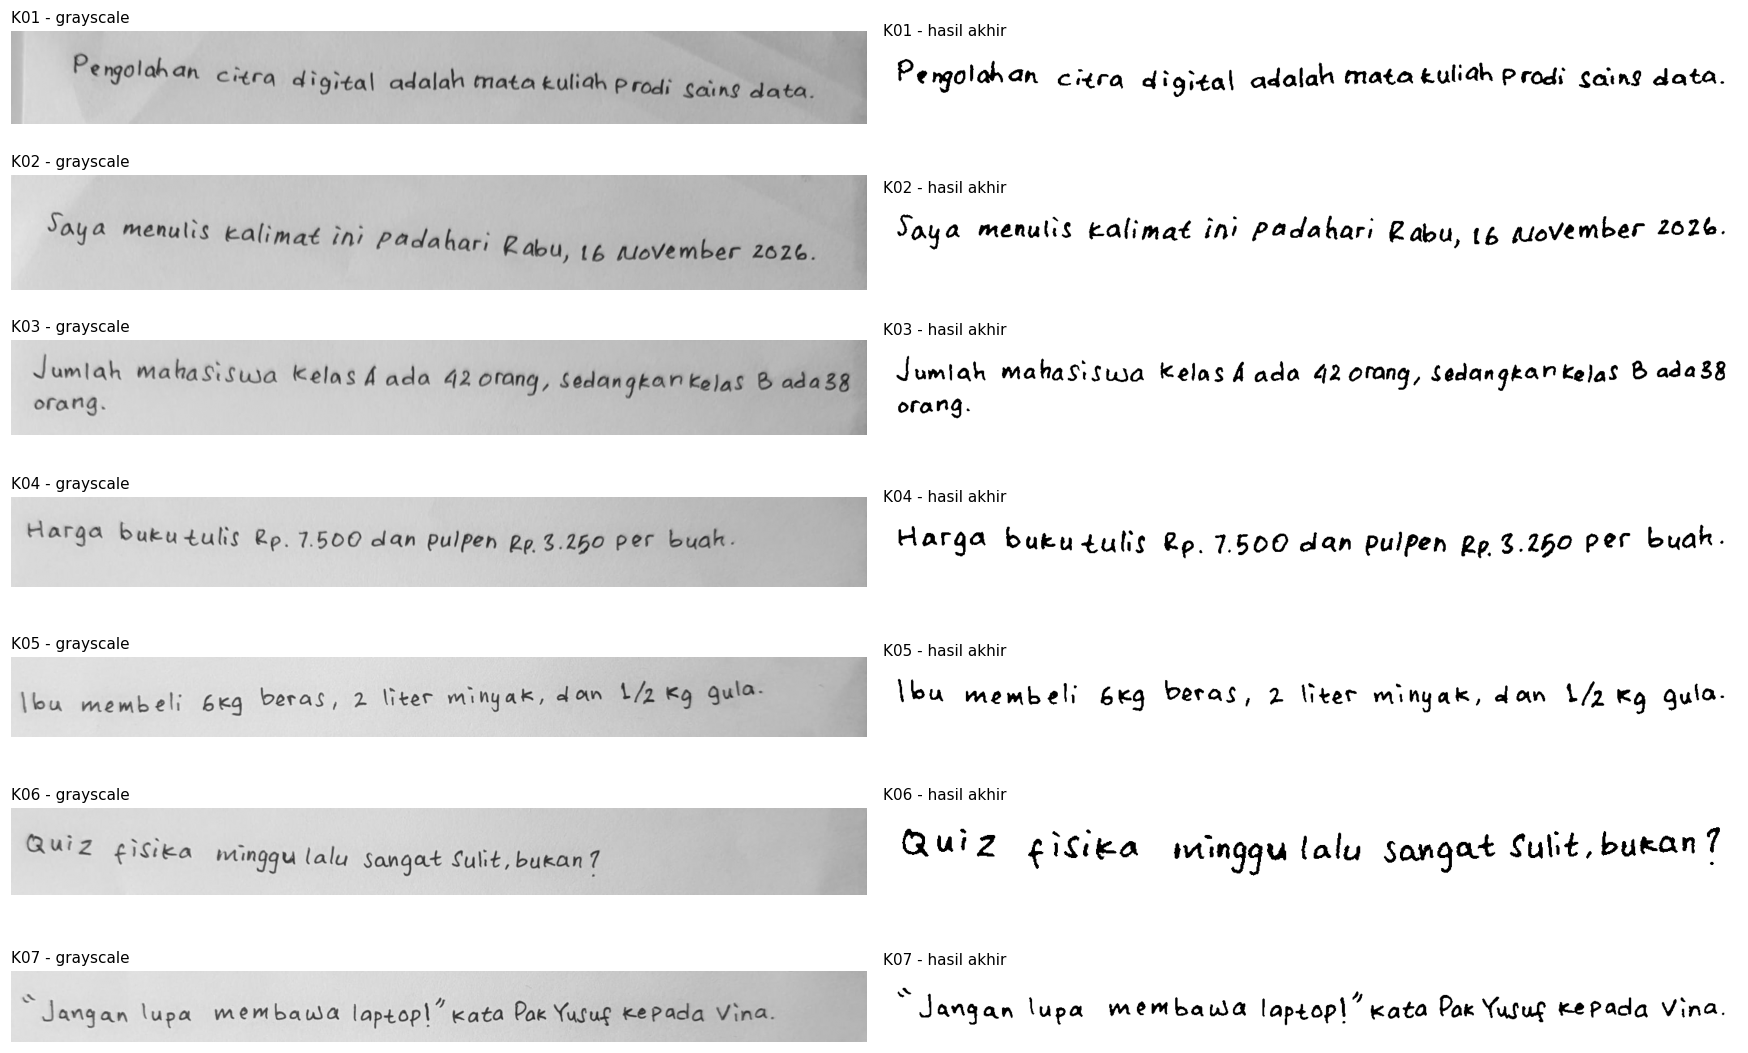

=== bergaris_single_line ===


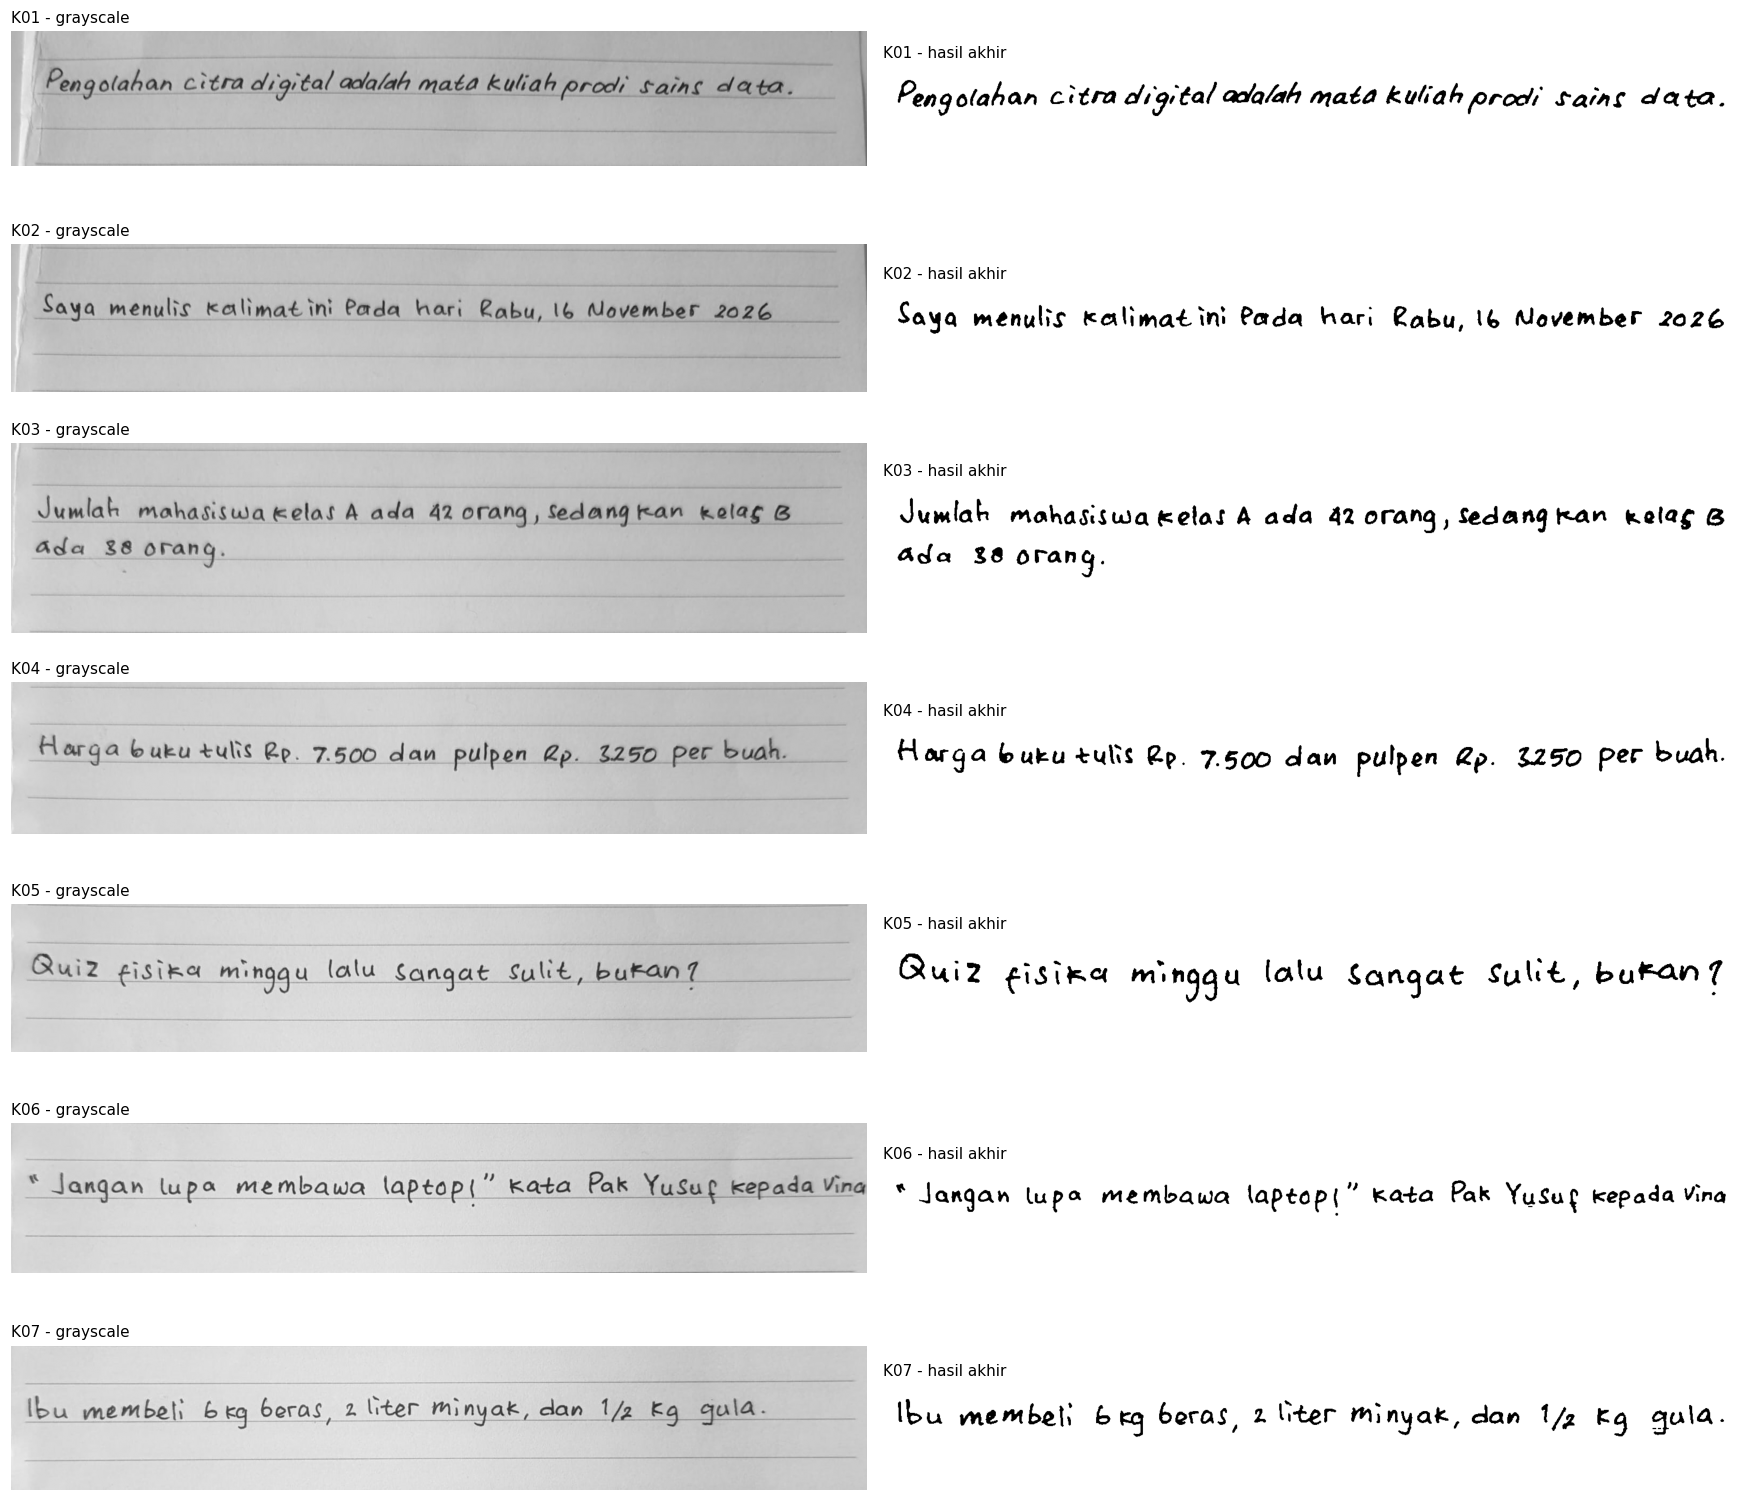

In [15]:
# Visualisasi perbandingan Grayscale vs Hasil Akhir untuk kelas 1 baris
for cls in ["polos_single_line", "bergaris_single_line"]:
    sub = df[df["class_name"] == cls]
    if len(sub) == 0:
        continue
    citra, judul = [], []
    for r in sub.itertuples():
        citra += [r.gray, r.final]
        judul += [f"{r.kode} - grayscale", f"{r.kode} - hasil akhir"]
    print(f"=== {cls} ===")
    tampil(citra, judul, ncols=2, lebar=16)

## 11. Tesseract OCR & Evaluasi CER / WER

In [16]:
def jarak_levenshtein(seq1, seq2):
    n, m = len(seq1), len(seq2)
    dp = list(range(m + 1))
    for i in range(1, n + 1):
        prev, dp[0] = dp[0], i
        for j in range(1, m + 1):
            temp = dp[j]
            cost = 0 if seq1[i - 1] == seq2[j - 1] else 1
            dp[j] = min(dp[j] + 1, dp[j - 1] + 1, prev + cost)
            prev = temp
    return dp[m]

def hitung_cer(gt, pred):
    if JIWER_TERSEDIA:
        return float(hitung_cer_jiwer(gt, pred))
    if len(gt) == 0:
        return 0.0 if len(pred) == 0 else 1.0
    return jarak_levenshtein(list(gt), list(pred)) / len(gt)

def hitung_wer(gt, pred):
    if JIWER_TERSEDIA:
        return float(hitung_wer_jiwer(gt, pred))
    gt_words, pred_words = gt.split(), pred.split()
    if len(gt_words) == 0:
        return 0.0 if len(pred_words) == 0 else 1.0
    return jarak_levenshtein(gt_words, pred_words) / len(gt_words)

def normalisasi_teks(teks):
    teks = str(teks).replace("\n", " ").strip()
    return re.sub(r"\s+", " ", teks)

def jalankan_ocr_baris(daftar_citra, lang="ind+eng", psm=7):
    if not PYTESSERACT_TERSEDIA:
        return ""
    konfig = f"--oem 3 --psm {psm}"
    hasil = []
    for img in daftar_citra:
        txt = pytesseract.image_to_string(img, lang=lang, config=konfig).strip()
        if txt:
            hasil.append(txt)
    return normalisasi_teks(" ".join(hasil))

# Ekspor ringkasan metrik pra-pemrosesan terlebih dahulu
ringkasan_pra = df[[
    "image_id", "source_type", "class_name", "paper_type", "layout_type",
    "lebar", "tinggi", "ambang_otsu", "px_garis_dihapus",
    "buang_kecil", "buang_sisa_garis", "buang_tepi", "sudut_deskew", "jumlah_baris"
]]
ringkasan_pra.to_csv(OUT_DIR / "ringkasan_prapemrosesan.csv", index=False)
display(ringkasan_pra)

# Jalankan Ablation Study OCR apabila Tesseract tersedia
if PYTESSERACT_TERSEDIA:
    eval_records = []
    for r in df.itertuples():
        gt = normalisasi_teks(r.ground_truth)
        is_multi = r.layout_type == "multi_line"
        psm_non_seg = 6 if is_multi else 7

        pred_exp0 = jalankan_ocr_baris([r.citra], psm=psm_non_seg)
        pred_exp1 = jalankan_ocr_baris([r.denoise], psm=psm_non_seg)
        pred_exp2 = jalankan_ocr_baris([255 - r.biner], psm=psm_non_seg)
        pred_exp3 = jalankan_ocr_baris([255 - r.bersih], psm=psm_non_seg)
        pred_exp4 = jalankan_ocr_baris(r.final_lines, psm=7)

        baris_eval = {
            "image_id": r.image_id,
            "source_type": r.source_type,
            "class_name": r.class_name,
            "ground_truth": gt,
            "pred_Exp0": pred_exp0,
            "pred_Exp4": pred_exp4,
        }
        if len(gt) > 0:
            for exp_nama, pred in [
                ("Exp0", pred_exp0), ("Exp1", pred_exp1), ("Exp2", pred_exp2),
                ("Exp3", pred_exp3), ("Exp4", pred_exp4)
            ]:
                baris_eval[f"CER_{exp_nama}"] = hitung_cer(gt, pred)
                baris_eval[f"WER_{exp_nama}"] = hitung_wer(gt, pred)
        eval_records.append(baris_eval)

    df_eval = pd.DataFrame(eval_records)
    df_eval.to_csv(OUT_DIR / "hasil_evaluasi_ocr.csv", index=False)
    display(df_eval)

    kolom_metrik = [c for c in df_eval.columns if c.startswith(("CER_", "WER_"))]
    if kolom_metrik:
        print("\n=== Rata-rata CER & WER per Kelas ===")
        display(df_eval.groupby("class_name")[kolom_metrik].mean().round(4))
else:
    print("[Info] Tesseract OCR belum terpasang di runtime ini. Ringkasan pra-pemrosesan telah disimpan ke:", OUT_DIR / "ringkasan_prapemrosesan.csv")

,image_id,source_type,class_name,paper_type,layout_type,lebar,tinggi,ambang_otsu,px_garis_dihapus,buang_kecil,buang_sisa_garis,buang_tepi,sudut_deskew,jumlah_baris
0,polos_single_line_K01_01,primer,polos_single_line,polos,single_line,1600,174,168.0,0,0,0,0,1.75,1
1,polos_single_line_K02_02,primer,polos_single_line,polos,single_line,1600,214,170.0,0,0,0,0,2.25,1
2,polos_single_line_K03_03,primer,polos_single_line,polos,single_line,1600,177,177.0,0,0,0,0,1.00,1
3,polos_single_line_K04_04,primer,polos_single_line,polos,single_line,1600,168,173.0,0,0,0,0,0.75,1
4,polos_single_line_K05_05,primer,polos_single_line,polos,single_line,1600,149,169.0,0,0,0,0,-1.25,1
5,polos_single_line_K06_06,primer,polos_single_line,polos,single_line,1600,163,170.0,0,0,0,0,1.75,1
6,polos_single_line_K07_07,primer,polos_single_line,polos,single_line,1600,133,170.0,0,0,0,0,0.00,1
7,bergaris_single_line_K01_01,primer,bergaris_single_line,bergaris,single_line,1599,251,170.0,0,0,0,1,0.25,1
8,bergaris_single_line_K02_02,primer,bergaris_single_line,bergaris,single_line,1599,276,169.0,0,0,0,1,0.25,1
9,bergaris_single_line_K03_03,primer,bergaris_single_line,bergaris,single_line,1599,355,170.0,0,0,0,0,0.00,1


,image_id,source_type,class_name,ground_truth,pred_Exp0,pred_Exp4
0,polos_single_line_K01_01,primer,polos_single_line,,Pengolahan citea digital adalah mata kuliah Pr...,Pengolahan citra digital adalah mata kuliah Pr...
1,polos_single_line_K02_02,primer,polos_single_line,,"Jaya menulis kalimat ini Padahari Rabu, (6 mov...","Saya menulis kalimat ini Padahari Rabu, 16 sov..."
2,polos_single_line_K03_03,primer,polos_single_line,,"Sen mahasiswa kelas 4 ada 42 orang, Sedangkan ...","Jumlah mahasiswa Kelas A ada 42 orang, Sedangk..."
3,polos_single_line_K04_04,primer,polos_single_line,,Harga buku tulis Rp. 7.500 dan pulpen Rp. 3.25...,Harga buku dulis Rp. 7.500 dan pulpen pp 3.150...
4,polos_single_line_K05_05,primer,polos_single_line,,"Ibu membeli 6eq beras, 2 liter minyak, don 1/2...","bu membeli 6Kg beras, 2 liter minyak, dan 1/2 ..."
5,polos_single_line_K06_06,primer,polos_single_line,,"Quiz £i<tea munggu lalu Sangat Sult, bukan 7","Quiz pisika minggu lalu sangat Sulit, bukan 7"
6,polos_single_line_K07_07,primer,polos_single_line,,“Jangan lupa membawa laptop” Kata Par Yugug ke...,"""Jangan lupa membawa laptop!” kata Por Yusup k..."
7,bergaris_single_line_K01_01,primer,bergaris_single_line,,Peng olahan citra digital adalah mata kuliah p...,Peng olahan citra digital adalah mata kuliah p...
8,bergaris_single_line_K02_02,primer,bergaris_single_line,,"Saya menulis kalimat ini Pada hari Rabu, lb No...","Saya menulis kalimatini Cada hari Rabu, 16 Nov..."
9,bergaris_single_line_K03_03,primer,bergaris_single_line,,"ip a. kelas A ada 42 orang, Sedang kan —","Jumlah ae Kelas A ada 42 orang, Sedangkan kelag B"
